# FAIRPATH-EDU
### Causal and Counterfactual Fairness in Early Student Risk Prediction
*An intersectional audit across gender, socioeconomic deprivation (IMD) and geographic region using OULAD*

**Authors:** Shreeya Kamath and Misha  |  **Course:** Fairness in Machine Learning (mini-project)

This notebook implements the full pipeline of the synopsis, stage by stage:

| Section | Synopsis stage | Objective |
|---|---|---|
| 1-2 | Setup, data download | - |
| 3 | Stage 1: data integration + early-window (day ≤ 28) features | Obj. 1 |
| 4 | Stage 2: exploratory disparity analysis, Simpson's paradox | Obj. 1 / 3 |
| 5-7 | Stage 3-4: grouped split, LR + XGBoost, predictive evaluation | Obj. 1 |
| 8-10 | Stage 5-6: formal fairness audit, significance tests, criteria incompatibility | Obj. 2 |
| 11 | Stage 7: SCM, backdoor sets, front-door check, adjusted effects, E-values | Obj. 3 |
| 12 | Stage 8: counterfactual sensitivity analysis | Obj. 3 |
| 13 | Stage 9: mitigation (reweighing, ExponentiatedGradient, optional post-processing) | Obj. 4 |
| 14-15 | Stage 10: SHAP / coefficients / subgroup errors, human-review notes, export | Obj. 4 |

**How to run in Colab:** `Runtime → Run all`. A CPU runtime is enough (no GPU needed). The dataset is downloaded automatically (UCI mirror); if the download is blocked you will be asked to upload the OULAD files. Expect roughly 15-30 minutes in total; lower `N_BOOT`, `N_PERM` and `N_XGB_CONFIGS` in the config cell for a quick dry run.

> **Ethical framing (from the synopsis):** predictions are decision-support signals for *supportive* outreach, never for automatic punishment. OULAD is UK-specific (2013-14), so numbers here illustrate a reproducible audit methodology, not current Indian higher education.

## 1. Setup and configuration

In [1]:
!pip -q install fairlearn shap xgboost statsmodels networkx seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.4/141.4 kB 10.7 MB/s eta 0:00:00


In [2]:
import os, re, io, json, zipfile, shutil, warnings, itertools, urllib.request, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy import stats
from IPython.display import display, Markdown

from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import confint_proportions_2indep
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, EqualizedOdds
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "figure.autolayout": True})

# ------------------------------- CONFIG (edit here) -------------------------------
SEED            = 42
CUTOFF_DAY      = 28        # early-warning window: only information up to the end of day 28 is used
EXCLUDE_EARLY_DEREG = False # True = drop students who already de-registered by CUTOFF_DAY (strictest leakage control)
THRESHOLD_RULE  = "recall_target"   # "recall_target" or "f1"
TARGET_RECALL   = 0.80      # support objective: catch >= 80% of truly at-risk students at the *validation* stage
MIN_GROUP_N     = 100       # smallest test-set group size that is reported/audited
MIN_CLASS_N     = 20        # smallest positives AND negatives per group
N_BOOT          = 300       # cluster-bootstrap replicates (resampling students)
N_PERM          = 2000      # permutation-test replicates
N_BOOT_CAUSAL   = 200
N_XGB_CONFIGS   = 12        # random-search configs for XGBoost
LR_GRID         = [0.01, 0.1, 1.0, 10.0]
PRIMARY_MODEL   = "XGB_full"        # model that gets the detailed audit (CIs, permutation tests)
MITIGATION_ATTR = "imd_group"       # attribute the mitigation targets
MITIGATION_CONSTRAINT = "EqualizedOdds"   # "EqualizedOdds" or "DemographicParity"
MITIGATION_FEATURES   = "full"      # "full" or "blind"
EG_EPS          = 0.02
N_STABILITY     = 3         # bootstrap refits for SHAP stability
rng_global = np.random.default_rng(SEED)

DATA_DIR = Path("/content/oulad");           DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT      = Path("/content/fairpath_outputs"); OUT.mkdir(parents=True, exist_ok=True)

def save_table(df_, name):
    df_.to_csv(OUT / f"{name}.csv"); return df_
def save_fig(name):
    plt.savefig(OUT / f"{name}.png", bbox_inches="tight")
print("Output folder:", OUT)

Output folder: /content/fairpath_outputs


## 2. Get the OULAD data
The cell tries the UCI mirror first, then the Open University site. If both fail (some networks block them) it asks you to **upload either the zip or the 7 CSV files** (`assessments, courses, studentAssessment, studentInfo, studentRegistration, studentVle, vle`). You can also mount Google Drive and copy the CSVs into `/content/oulad`.

In [3]:
REQUIRED = ["assessments.csv","courses.csv","studentAssessment.csv","studentInfo.csv",
            "studentRegistration.csv","studentVle.csv","vle.csv"]
URLS = ["https://archive.ics.uci.edu/static/public/349/open+university+learning+analytics+dataset.zip",
        "https://analyse.kmi.open.ac.uk/open_dataset/download"]

def have_all(d): return all((d / f).exists() for f in REQUIRED)

def harvest_csvs(src_dir):
    # extract nested zips, then copy all CSVs into DATA_DIR
    for _ in range(3):
        for z in list(Path(src_dir).rglob("*.zip")):
            try:
                with zipfile.ZipFile(z) as zf: zf.extractall(z.parent / (z.stem + "_x"))
                z.unlink()
            except Exception as e: print("  zip problem:", e)
    for f in Path(src_dir).rglob("*.csv"):
        shutil.copy(f, DATA_DIR / f.name)

def try_download():
    for url in URLS:
        try:
            print("Trying", url)
            raw = Path("/content/oulad_raw"); raw.mkdir(exist_ok=True)
            zpath = raw / "download.zip"
            urllib.request.urlretrieve(url, zpath)
            if zipfile.is_zipfile(zpath):
                harvest_csvs(raw)
                if have_all(DATA_DIR): return True
        except Exception as e:
            print("  failed:", repr(e)[:150])
    return False

if not have_all(DATA_DIR):
    ok = try_download()
    if not ok:
        print("\nAutomatic download failed -> please upload the zip or the CSV files now.")
        from google.colab import files
        up = files.upload()
        raw = Path("/content/oulad_raw"); raw.mkdir(exist_ok=True)
        for name, content in up.items():
            (raw / name).write_bytes(content)
        harvest_csvs(raw)
assert have_all(DATA_DIR), f"Missing files in {DATA_DIR}: {[f for f in REQUIRED if not (DATA_DIR/f).exists()]}"
print("All OULAD tables found in", DATA_DIR)

Trying https://archive.ics.uci.edu/static/public/349/open+university+learning+analytics+dataset.zip
All OULAD tables found in /content/oulad


## 3. Stage 1: data integration and early-window features (Objective 1)
Only information available **by the end of day 28** is used: VLE clicks with `date ≤ 28`, assessment submissions with `date_submitted ≤ 28`, assessments *due* by day 28, and de-registration only if it happened by day 28. The target is `at_risk = Fail or Withdrawn`.

In [4]:
KEYS = ["code_module","code_presentation","id_student"]
PKEYS = ["code_module","code_presentation"]

NA = ["?", "", " ", "NA"]       # real OULAD files use "?" for missing values (e.g. exam dates, IMD band)
si  = pd.read_csv(DATA_DIR/"studentInfo.csv", na_values=NA)
reg = pd.read_csv(DATA_DIR/"studentRegistration.csv", na_values=NA)
asm = pd.read_csv(DATA_DIR/"assessments.csv", na_values=NA)
sa  = pd.read_csv(DATA_DIR/"studentAssessment.csv", na_values=NA)
vle = pd.read_csv(DATA_DIR/"vle.csv", usecols=["id_site","code_module","code_presentation","activity_type"], na_values=NA)
for _df, _cols in [(reg, ["date_registration","date_unregistration"]), (asm, ["date","weight"]),
                   (sa, ["date_submitted","score"]), (si, ["num_of_prev_attempts","studied_credits"])]:
    for _c in _cols: _df[_c] = pd.to_numeric(_df[_c], errors="coerce")
print("studentInfo rows:", len(si), "(published: 32,593)")

# ---- VLE: read in chunks, keep only days <= CUTOFF_DAY (temporal-leakage control) ----
chunks = []
for ch in pd.read_csv(DATA_DIR/"studentVle.csv", chunksize=2_000_000,
                      usecols=KEYS+["id_site","date","sum_click"], na_values=NA):
    ch["date"] = pd.to_numeric(ch["date"], errors="coerce"); ch["sum_click"] = pd.to_numeric(ch["sum_click"], errors="coerce")
    chunks.append(ch[ch["date"] <= CUTOFF_DAY])
svle = pd.concat(chunks, ignore_index=True); del chunks
svle = svle.merge(vle, on=["id_site"]+PKEYS, how="left")
print("VLE rows kept (day <= %d): %s" % (CUTOFF_DAY, f"{len(svle):,}"))
assert svle["date"].max() <= CUTOFF_DAY

g = svle.groupby(KEYS)
vf = pd.DataFrame({
    "total_clicks": g["sum_click"].sum(),
    "active_days": g["date"].nunique(),
    "unique_activity_types": g["activity_type"].nunique(),
}).reset_index()
vf["clicks_per_active_day"] = np.where(vf.active_days > 0, vf.total_clicks / vf.active_days.clip(lower=1), 0.0)

# ---- Assessments ----
asm_early = asm[asm["date"] <= CUTOFF_DAY]                       # assessments *due* by the cutoff
ac = asm_early.groupby(PKEYS).size().rename("assessment_count").reset_index()
sa2 = sa.merge(asm[["id_assessment","code_module","code_presentation","date"]], on="id_assessment", how="left")
sa2 = sa2[sa2["date_submitted"] <= CUTOFF_DAY]                    # submissions *made* by the cutoff
sa2["late"] = (sa2["date_submitted"] > sa2["date"]).astype(int)   # NaN due-date (exams) -> not late
sg = sa2.groupby(KEYS)
af = pd.DataFrame({"submitted_assessments": sg.size(),
                   "mean_score": sg["score"].mean(),
                   "late_submissions": sg["late"].sum()}).reset_index()

# ---- Registration (only what is known by the cutoff) ----
reg["reg_lead_days"] = -reg["date_registration"]                 # positive = registered before course start
reg["early_dereg"] = (reg["date_unregistration"] <= CUTOFF_DAY).astype(int)
regf = reg[KEYS+["reg_lead_days","early_dereg"]]

# ---- Master table ----
EDU_ORD = {"No Formal quals":0,"Lower Than A Level":1,"A Level or Equivalent":2,"HE Qualification":3,"Post Graduate Qualification":4}
EDU_INV = {v:k for k,v in EDU_ORD.items()}
AGE_ORD = {"0-35":0,"35-55":1,"55<=":2}
IMD_LABELS = [f"{10*k}-{10*k+10}%" for k in range(10)]
def imd_to_ord(s):
    if pd.isna(s): return np.nan
    m = re.match(r"\s*(\d+)", str(s)); return int(m.group(1))//10 if m else np.nan

df = (si.merge(regf, on=KEYS, how="left").merge(vf, on=KEYS, how="left")
        .merge(ac, on=PKEYS, how="left").merge(af, on=KEYS, how="left"))
for c in ["total_clicks","active_days","unique_activity_types","clicks_per_active_day",
          "assessment_count","submitted_assessments","late_submissions","early_dereg"]:
    df[c] = df[c].fillna(0)
df["reg_lead_days"] = df["reg_lead_days"].fillna(df["reg_lead_days"].median())

df["imd_ord"]  = df["imd_band"].map(imd_to_ord)
df["imd_band"] = df["imd_ord"].map(lambda k: IMD_LABELS[int(k)] if pd.notna(k) else "Unknown")
df["imd_group"] = pd.cut(df["imd_ord"], bins=[-1,2,6,9],
                         labels=["IMD_High_Depr","IMD_Mid","IMD_Low_Depr"]).astype(object)   # NaN stays NaN
df["highest_education_ord"] = df["highest_education"].map(EDU_ORD)
df["age_ord"] = df["age_band"].map(AGE_ORD)
assert df["highest_education_ord"].notna().all() and df["age_ord"].notna().all(), "unexpected category labels"
df["gender_F"] = (df["gender"] == "F").astype(float)
df["log_total_clicks"] = np.log1p(df["total_clicks"])
df["at_risk"] = df["final_result"].isin(["Fail","Withdrawn"]).astype(int)
df["y"] = df["at_risk"]
df["gender_x_imd"] = np.where(df.imd_group.notna(), df.gender + "|" + df.imd_group.fillna(""), None)
df["gender_x_imd_x_region"] = np.where(df.imd_group.notna(), df.gender + "|" + df.imd_group.fillna("") + "|" + df.region, None)

if EXCLUDE_EARLY_DEREG:
    df = df[df.early_dereg == 0]
df = df.reset_index(drop=True)

print("Final cohort:", df.shape, "| at-risk prevalence: %.3f" % df.y.mean())
print(df.final_result.value_counts().to_dict())
display(df[["total_clicks","active_days","unique_activity_types","assessment_count",
            "submitted_assessments","mean_score","late_submissions","early_dereg","reg_lead_days"]].describe().T.round(2))

studentInfo rows: 32593 (published: 32,593)
VLE rows kept (day <= 28): 2,847,851
Final cohort: (32593, 32) | at-risk prevalence: 0.528
{'Pass': 12361, 'Withdrawn': 10156, 'Fail': 7052, 'Distinction': 3024}


,count,mean,std,min,25%,50%,75%,max
total_clicks,32593.0,309.69,414.48,0.0,47.0,179.0,414.0,7697.0
active_days,32593.0,12.81,10.65,0.0,4.0,11.0,19.0,54.0
unique_activity_types,32593.0,6.19,3.11,0.0,5.0,7.0,8.0,14.0
assessment_count,32593.0,0.87,0.44,0.0,1.0,1.0,1.0,2.0
submitted_assessments,32593.0,0.79,0.80,0.0,0.0,1.0,1.0,12.0
mean_score,20819.0,72.81,21.90,0.0,65.0,78.0,88.0,100.0
late_submissions,32593.0,0.16,0.37,0.0,0.0,0.0,0.0,2.0
early_dereg,32593.0,0.16,0.36,0.0,0.0,0.0,0.0,1.0
reg_lead_days,32593.0,69.39,49.23,-167.0,29.0,57.0,100.0,322.0


**Leakage note.** `early_dereg` (de-registered by day 28) is legitimately known at the cut-off, but it is close to the label *Withdrawn*. It is kept because the synopsis lists it; set `EXCLUDE_EARLY_DEREG = True` in the config to remove those students and see how much of the performance depends on it.

## 4. Stage 2: exploratory disparity analysis (+ Simpson's paradox)
Sample sizes, prevalence and missingness by group, then **pooled vs within-module** comparisons.


=== gender ===


,n,at_risk_rate,mean_clicks,pct_no_submission
gender,,,,
F,14718,0.516,242.705,0.364
M,17875,0.538,364.844,0.358



=== imd_group ===


,n,at_risk_rate,mean_clicks,pct_no_submission
imd_group,,,,
IMD_High_Depr,10481,0.617,270.438,0.406
IMD_Low_Depr,8177,0.458,338.189,0.323
IMD_Mid,12824,0.516,307.182,0.360



=== region ===


,n,at_risk_rate,mean_clicks,pct_no_submission
region,,,,
East Anglian Region,3340,0.510,298.649,0.371
East Midlands Region,2365,0.543,293.125,0.381
Ireland,1184,0.451,360.052,0.197
London Region,3216,0.576,277.051,0.416
North Region,1823,0.495,387.120,0.344
North Western Region,2906,0.598,290.466,0.423
Scotland,3446,0.510,357.147,0.329
South East Region,2111,0.485,307.303,0.350
South Region,3092,0.476,321.440,0.356



=== gender_x_imd ===


,n,at_risk_rate,mean_clicks,pct_no_submission
gender_x_imd,,,,
F|IMD_High_Depr,5251,0.601,212.207,0.405
F|IMD_Low_Depr,3278,0.430,272.464,0.322
F|IMD_Mid,5886,0.496,242.414,0.360
M|IMD_High_Depr,5230,0.634,328.902,0.407
M|IMD_Low_Depr,4899,0.476,382.166,0.324
M|IMD_Mid,6938,0.532,362.129,0.360



Missingness by IMD availability:


,mean_score
imd_missing,
False,0.366305
True,0.217822


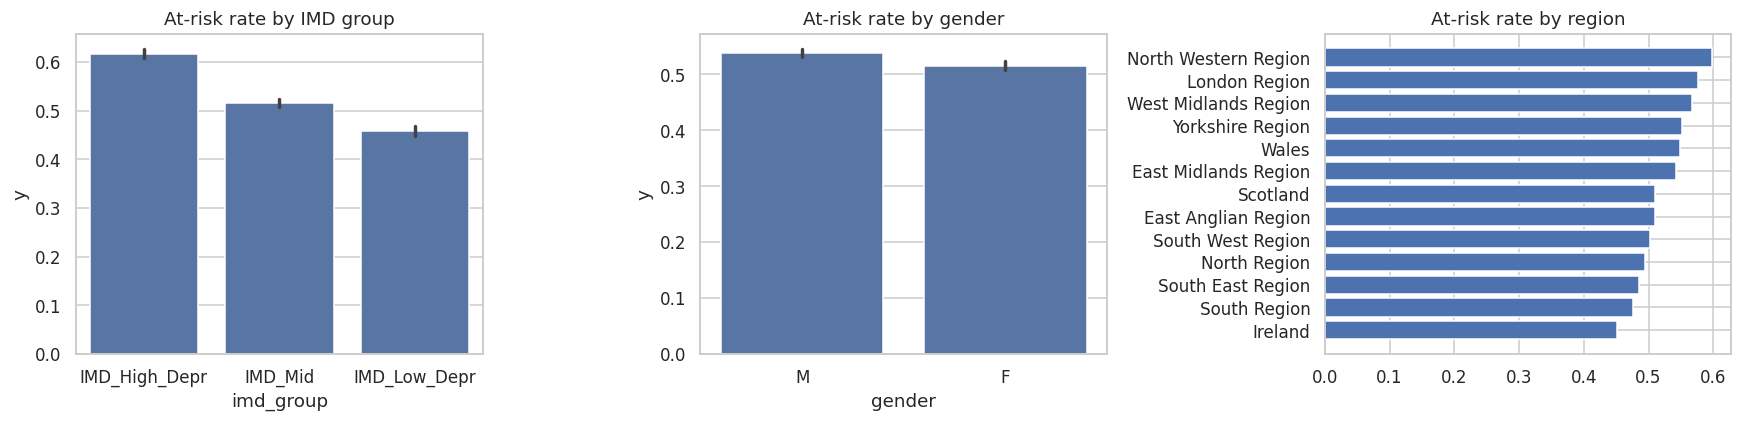

In [5]:
def prevalence_table(col, min_n=1):
    t = df.dropna(subset=[col]).groupby(col).agg(n=("y","size"), at_risk_rate=("y","mean"),
        mean_clicks=("total_clicks","mean"), pct_no_submission=("submitted_assessments", lambda s: (s==0).mean()))
    return t[t.n>=min_n].round(3)

for col in ["gender","imd_group","region","gender_x_imd"]:
    print(f"\n=== {col} ==="); display(save_table(prevalence_table(col), f"eda_{col}"))

print("\nMissingness by IMD availability:"); display(df.assign(imd_missing=df.imd_group.isna()).groupby("imd_missing")[["mean_score"]].agg(lambda s: s.isna().mean()))

fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.barplot(data=df.dropna(subset=["imd_group"]), x="imd_group", y="y", order=["IMD_High_Depr","IMD_Mid","IMD_Low_Depr"], ax=axes[0]); axes[0].set_title("At-risk rate by IMD group")
sns.barplot(data=df, x="gender", y="y", ax=axes[1]); axes[1].set_title("At-risk rate by gender")
rr = df.groupby("region").y.mean().sort_values(); axes[2].barh(rr.index, rr.values); axes[2].set_title("At-risk rate by region")
save_fig("eda_prevalence"); plt.show()

In [6]:
# ---------- Simpson's paradox / composition check ----------
def simpson_table(d, group_col, outcome_col, comp, ref, strata_col="code_module"):
    # pooled and within-stratum risk difference (comp - ref) + Mantel-Haenszel common odds ratio
    dd = d[d[group_col].isin([comp, ref])].copy()
    dd["is_comp"] = (dd[group_col] == comp).astype(int)
    pooled = dd.groupby("is_comp")[outcome_col].mean()
    pooled_rd = pooled.get(1, np.nan) - pooled.get(0, np.nan)
    rows, tables = [], []
    for s, sub in dd.groupby(strata_col):
        a = ((sub.is_comp==1)&(sub[outcome_col]==1)).sum(); b = ((sub.is_comp==1)&(sub[outcome_col]==0)).sum()
        c = ((sub.is_comp==0)&(sub[outcome_col]==1)).sum(); e = ((sub.is_comp==0)&(sub[outcome_col]==0)).sum()
        n1, n0 = a+b, c+e
        if n1 >= 20 and n0 >= 20:
            rows.append({"stratum": s, "n_comp": n1, "n_ref": n0, "rd": a/n1 - c/n0})
            if min(a,b,c,e) > 0 or True: tables.append(np.array([[a,b],[c,e]]) + 0.0)
    st = pd.DataFrame(rows)
    out = {"pooled_rd": pooled_rd, "n_strata": len(st),
           "within_rd_mean(weighted)": np.average(st.rd, weights=st.n_comp+st.n_ref) if len(st) else np.nan,
           "n_strata_sign_differs_from_pooled": int((np.sign(st.rd) != np.sign(pooled_rd)).sum()) if len(st) else 0}
    try:
        sT = StratifiedTable([t + 0.5 for t in tables]); out["MH_common_OR"] = sT.oddsratio_pooled
    except Exception: out["MH_common_OR"] = np.nan
    out["paradox_flag"] = bool(out["n_strata"] > 0 and out["n_strata_sign_differs_from_pooled"] == out["n_strata"])
    return out, st

simp = []
for gcol, comp, ref in [("gender","F","M"), ("imd_group","IMD_High_Depr","IMD_Low_Depr")]:
    for strata in ["code_module", "presentation_key"]:
        if strata == "presentation_key": df["presentation_key"] = df.code_module + "_" + df.code_presentation
        o, st = simpson_table(df, gcol, "y", comp, ref, strata)
        simp.append({"group": f"{comp} vs {ref}", "outcome": "observed at-risk", "strata": strata, **o})
# region: each region vs the rest
for r in sorted(df.region.unique()):
    d2 = df.assign(reg_bin=np.where(df.region==r, "this", "rest"))
    o, _ = simpson_table(d2, "reg_bin", "y", "this", "rest", "code_module")
    simp.append({"group": f"{r} vs rest", "outcome": "observed at-risk", "strata": "code_module", **o})
simp = pd.DataFrame(simp); save_table(simp, "simpson_observed")
display(simp.round(3))
print("Rows with paradox_flag=True are comparisons where pooled direction is reversed in EVERY stratum (a full Simpson's reversal).")
print("Partial differences (n_strata_sign_differs_from_pooled > 0) still show that module composition matters.")

,group,outcome,strata,pooled_rd,n_strata,within_rd_mean(weighted),n_strata_sign_differs_from_pooled,MH_common_OR,paradox_flag
0,F vs M,observed at-risk,code_module,-0.022,7,-0.014,2,0.962,False
1,F vs M,observed at-risk,presentation_key,-0.022,22,-0.014,8,0.964,False
2,IMD_High_Depr vs IMD_Low_Depr,observed at-risk,code_module,0.160,7,0.161,0,1.951,False
3,IMD_High_Depr vs IMD_Low_Depr,observed at-risk,presentation_key,0.160,22,0.161,0,1.947,False
4,East Anglian Region vs rest,observed at-risk,code_module,-0.020,7,-0.014,2,0.944,False
5,East Midlands Region vs rest,observed at-risk,code_module,0.016,7,0.019,3,1.085,False
6,Ireland vs rest,observed at-risk,code_module,-0.080,5,-0.088,0,0.694,False
7,London Region vs rest,observed at-risk,code_module,0.054,7,0.056,2,1.261,False
8,North Region vs rest,observed at-risk,code_module,-0.035,7,-0.036,1,0.830,False
9,North Western Region vs rest,observed at-risk,code_module,0.077,7,0.079,1,1.376,False


Rows with paradox_flag=True are comparisons where pooled direction is reversed in EVERY stratum (a full Simpson's reversal).
Partial differences (n_strata_sign_differs_from_pooled > 0) still show that module composition matters.


## 5. Stage 3: leakage-safe split (grouped by `id_student`, stratified by module × target)
60 / 20 / 20 train / validation / locked test. A student never appears in more than one split. The test set is only used for final reporting.

In [7]:
strat = (df.code_module + "_" + df.y.astype(str)).values
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(df, strat, groups=df.id_student.values)]
test_idx, val_idx = folds[0], folds[1]
train_idx = np.concatenate(folds[2:])
train, val, test = df.iloc[train_idx].copy(), df.iloc[val_idx].copy(), df.iloc[test_idx].copy()

# --- checks ---
s_tr, s_va, s_te = set(train.id_student), set(val.id_student), set(test.id_student)
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "student leakage across splits!"
print("No student appears in more than one split.")
summ = pd.DataFrame({k: {"n": len(v), "at_risk_rate": v.y.mean(), "pct_female": (v.gender=="F").mean(),
                         "pct_IMD_high_depr": (v.imd_group=="IMD_High_Depr").mean()} for k, v in
                     {"train":train,"val":val,"test":test}.items()}).T.round(3)
display(summ)
print("Module representation (%):"); display((pd.concat({"train":train.code_module.value_counts(normalize=True),
      "val":val.code_module.value_counts(normalize=True),"test":test.code_module.value_counts(normalize=True)},axis=1)*100).round(1))

No student appears in more than one split.


,n,at_risk_rate,pct_female,pct_IMD_high_depr
train,19572.0,0.530,0.451,0.324
val,6532.0,0.528,0.451,0.314
test,6489.0,0.522,0.453,0.323


Module representation (%):


,train,val,test
code_module,,,
BBB,24.1,24.7,24.3
FFF,24.0,23.2,23.9
DDD,19.2,19.0,19.7
CCC,13.5,14.0,13.5
EEE,8.9,9.6,8.6
GGG,8.0,7.4,7.6
AAA,2.4,2.1,2.4


## 6. Stage 3: models (regularised logistic regression and XGBoost)
Four model families are trained so that the *role of the sensitive attributes* can be tested (inclusion/exclusion ablation):

* `LR_full`, `XGB_full`: all 18 candidate predictors (gender, region, IMD band are included)
* `LR_blind`, `XGB_blind`: same without gender, region and IMD band ("fairness through unawareness")

Hyper-parameters and the decision threshold are chosen **on the validation set only**. The threshold rule is *the highest threshold that still recovers ≥ `TARGET_RECALL` of at-risk students* (the support-use objective: missed students are the costly error), not 0.50.

In [8]:
CAT = ["gender","region","imd_band","highest_education","age_band","disability"]
NUM = ["num_of_prev_attempts","studied_credits","reg_lead_days","early_dereg","total_clicks","active_days",
       "unique_activity_types","clicks_per_active_day","assessment_count","submitted_assessments","mean_score","late_submissions"]
LOG_COLS = ["total_clicks","clicks_per_active_day"]
SENS_PRIMARY = ["gender","region","imd_band"]
FEATS_FULL  = CAT + NUM
FEATS_BLIND = [f for f in FEATS_FULL if f not in SENS_PRIMARY]
assert len(FEATS_FULL) == 18, len(FEATS_FULL)

def make_preprocessor(feats):
    cat  = [c for c in feats if c in CAT]
    logc = [c for c in feats if c in LOG_COLS]
    num  = [c for c in feats if c in NUM and c not in LOG_COLS]
    tr = []
    if cat:  tr.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    if num:  tr.append(("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), num))
    if logc: tr.append(("log", Pipeline([("lg", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                         ("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), logc))
    return ColumnTransformer(tr, remainder="drop", verbose_feature_names_out=False)

def choose_threshold(y, p):
    y = np.asarray(y); p = np.asarray(p)
    if THRESHOLD_RULE == "recall_target":
        for t in np.unique(np.quantile(p, np.linspace(0, 1, 1001)))[::-1]:
            if (p[y==1] >= t).mean() >= TARGET_RECALL: return float(t)
        return float(p.min())
    ts = np.unique(np.quantile(p, np.linspace(0.01, 0.99, 197)))
    return float(ts[np.argmax([f1_score(y, p >= t) for t in ts])])

XGB_SPACE = {"n_estimators":[200,400], "max_depth":[3,4,6], "learning_rate":[0.03,0.06,0.1],
             "subsample":[0.8,1.0], "colsample_bytree":[0.6,0.8,1.0], "min_child_weight":[1,5]}

def train_model(kind, feats, name, w_train=None):
    pre = make_preprocessor(feats).fit(train[feats])
    Xtr, Xva = pre.transform(train[feats]), pre.transform(val[feats])
    ytr, yva = train.y.values, val.y.values
    best = (-1, None, None)
    if kind == "LR":
        cands = [{"C": C} for C in LR_GRID]
    else:
        cands = list(ParameterSampler(XGB_SPACE, n_iter=N_XGB_CONFIGS, random_state=SEED))
    for prm in cands:
        if kind == "LR": clf = LogisticRegression(max_iter=3000, **prm)
        else: clf = XGBClassifier(**prm, eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=-1)
        clf.fit(Xtr, ytr, sample_weight=w_train)
        auc = roc_auc_score(yva, clf.predict_proba(Xva)[:,1])
        if auc > best[0]: best = (auc, clf, prm)
    pipe = Pipeline([("pre", pre), ("clf", best[1])])          # already fitted components
    pv = pipe.predict_proba(val[feats])[:,1]
    return {"name": name, "kind": kind, "feats": feats, "pipe": pipe, "thr": choose_threshold(yva, pv),
            "params": best[2], "val_auc": best[0]}

def predict_p(M, d): return M["pipe"].predict_proba(d[M["feats"]])[:,1]

MODELS = {}
t0 = time.time()
for kind in ["LR","XGB"]:
    for tag, feats in [("full", FEATS_FULL), ("blind", FEATS_BLIND)]:
        nm = f"{kind}_{tag}"; MODELS[nm] = train_model(kind, feats, nm)
        print(f"{nm:10s} val AUC={MODELS[nm]['val_auc']:.4f}  thr={MODELS[nm]['thr']:.3f}  params={MODELS[nm]['params']}")
print("Training time: %.0fs" % (time.time()-t0))

LR_full    val AUC=0.8246  thr=0.401  params={'C': 0.1}
LR_blind   val AUC=0.8186  thr=0.399  params={'C': 0.1}
XGB_full   val AUC=0.8446  thr=0.403  params={'subsample': 1.0, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
XGB_blind  val AUC=0.8405  thr=0.397  params={'subsample': 0.8, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.06, 'colsample_bytree': 0.6}
Training time: 26s


## 7. Stage 4: predictive evaluation on the locked test set
Balanced accuracy, precision, recall, F1, ROC-AUC, PR-AUC, Brier, ECE, confusion matrices; cluster-bootstrap 95% CIs (students resampled); threshold sensitivity; calibration.

,BalAcc,Precision,Recall,F1,ROC_AUC,PR_AUC,Brier,ECE,Flag_rate
model,,,,,,,,,
LR_full,"0.726 [0.717,0.737]","0.715 [0.702,0.729]","0.802 [0.789,0.813]","0.756 [0.746,0.766]","0.829 [0.821,0.838]","0.867 [0.859,0.875]","0.166 [0.162,0.170]","0.013 [0.010,0.024]","0.585 [0.573,0.596]"
LR_blind,"0.722 [0.713,0.731]","0.711 [0.697,0.723]","0.798 [0.783,0.810]","0.752 [0.742,0.763]","0.823 [0.814,0.832]","0.862 [0.854,0.870]","0.168 [0.165,0.172]","0.013 [0.011,0.025]","0.586 [0.574,0.597]"
XGB_full,"0.742 [0.732,0.752]","0.732 [0.720,0.746]","0.804 [0.793,0.816]","0.767 [0.757,0.777]","0.845 [0.836,0.853]","0.880 [0.873,0.887]","0.158 [0.154,0.162]","0.014 [0.011,0.025]","0.573 [0.561,0.585]"
XGB_blind,"0.739 [0.730,0.749]","0.729 [0.717,0.742]","0.805 [0.793,0.816]","0.765 [0.756,0.776]","0.842 [0.833,0.850]","0.878 [0.870,0.885]","0.159 [0.155,0.163]","0.012 [0.009,0.023]","0.576 [0.563,0.588]"


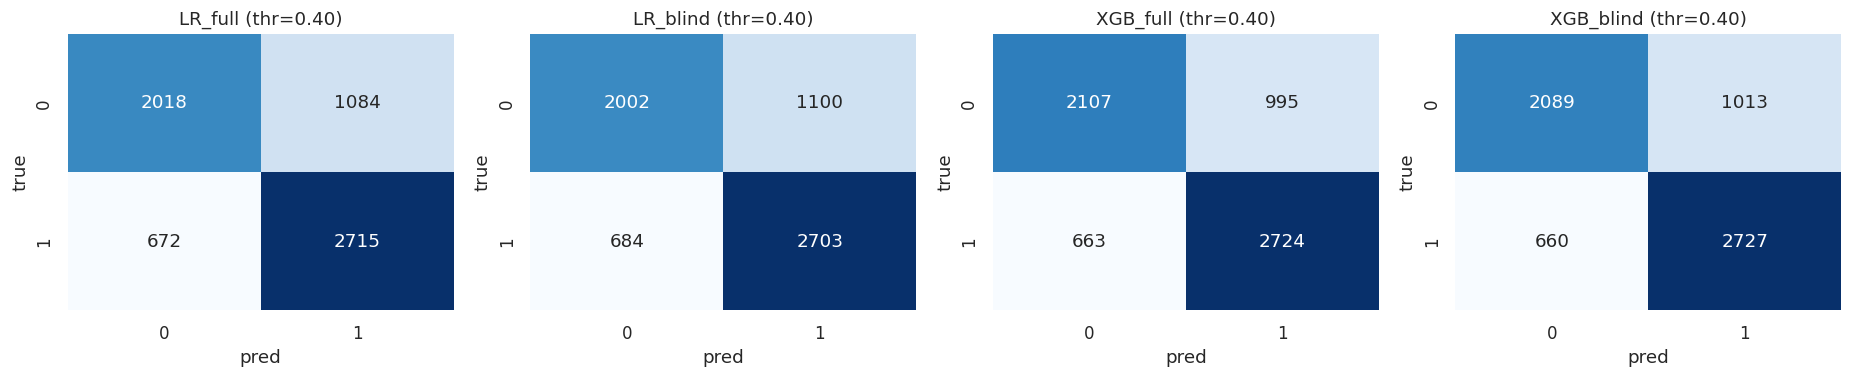

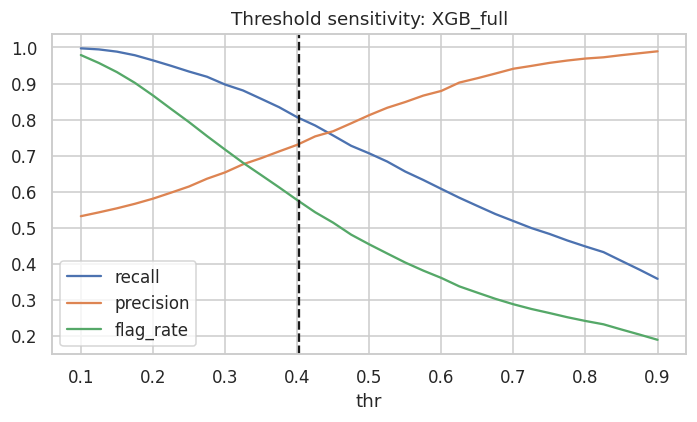

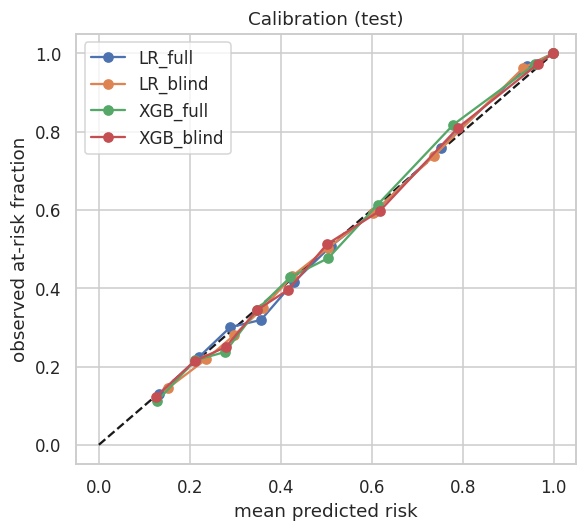

In [9]:
def ece_score(y, p, bins=10):
    y = np.asarray(y, float); p = np.asarray(p, float)
    b = np.minimum((p*bins).astype(int), bins-1); tot = 0.0
    for k in range(bins):
        m = b == k
        if m.any(): tot += m.mean() * abs(y[m].mean() - p[m].mean())
    return tot

def perf(y, p, thr, yhat=None):
    yhat = (p >= thr).astype(int) if yhat is None else yhat
    return {"BalAcc": balanced_accuracy_score(y, yhat), "Precision": precision_score(y, yhat, zero_division=0),
            "Recall": recall_score(y, yhat), "F1": f1_score(y, yhat), "ROC_AUC": roc_auc_score(y, p),
            "PR_AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p), "ECE": ece_score(y, p),
            "Flag_rate": yhat.mean()}

class ClusterBoot:
    # resample whole students (clusters) with replacement
    def __init__(self, groups, seed=SEED):
        codes, _ = pd.factorize(pd.Series(groups))
        self.order = np.argsort(codes, kind="stable"); self.counts = np.bincount(codes)
        self.starts = np.r_[0, np.cumsum(self.counts)[:-1]]; self.rng = np.random.default_rng(seed)
    def sample(self):
        k = self.rng.integers(0, len(self.counts), len(self.counts))
        return np.concatenate([self.order[self.starts[i]:self.starts[i]+self.counts[i]] for i in k])

# ---- store test-set predictions for every model ----
T = test.copy(); yT = T.y.values
RESULTS = {}
def register(name, p, yhat, thr=None):
    p = np.clip(np.asarray(p, dtype=float), 0.0, 1.0)      # guards against float round-off (e.g. ExponentiatedGradient mixtures)
    RESULTS[name] = {"p": p, "yhat": yhat, "thr": thr}
    T[f"p_{name}"] = p; T[f"yhat_{name}"] = yhat
for nm, M in MODELS.items():
    p = predict_p(M, T); register(nm, p, (p >= M["thr"]).astype(int), M["thr"])

boot = ClusterBoot(T.id_student.values)
idxs = [boot.sample() for _ in range(N_BOOT)]
rows = []
for nm in MODELS:
    base = perf(yT, RESULTS[nm]["p"], RESULTS[nm]["thr"])
    bs = pd.DataFrame([perf(yT[i], RESULTS[nm]["p"][i], RESULTS[nm]["thr"]) for i in idxs])
    row = {"model": nm}
    for k, v in base.items():
        lo, hi = bs[k].quantile([.025,.975]); row[k] = f"{v:.3f} [{lo:.3f},{hi:.3f}]"
    rows.append(row)
perf_table = pd.DataFrame(rows).set_index("model"); save_table(perf_table, "test_performance")
display(perf_table)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, nm in zip(axes, MODELS):
    cm = confusion_matrix(yT, RESULTS[nm]["yhat"]); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{nm} (thr={MODELS[nm]['thr']:.2f})"); ax.set_xlabel("pred"); ax.set_ylabel("true")
save_fig("confusion_matrices"); plt.show()

# threshold sensitivity (primary model)
ts = np.linspace(0.1, 0.9, 33); pm = RESULTS[PRIMARY_MODEL]["p"]
sens = pd.DataFrame({"thr": ts, "recall": [recall_score(yT, pm>=t) for t in ts],
                     "precision": [precision_score(yT, pm>=t, zero_division=0) for t in ts],
                     "flag_rate": [(pm>=t).mean() for t in ts]})
fig, ax = plt.subplots(figsize=(6.5,4)); sens.set_index("thr").plot(ax=ax); ax.axvline(MODELS[PRIMARY_MODEL]["thr"], ls="--", c="k")
ax.set_title(f"Threshold sensitivity: {PRIMARY_MODEL}"); save_fig("threshold_sensitivity"); plt.show()

# calibration
fig, ax = plt.subplots(figsize=(5.5,5)); ax.plot([0,1],[0,1],"k--")
for nm in MODELS:
    fr, mp = calibration_curve(yT, RESULTS[nm]["p"], n_bins=10, strategy="quantile"); ax.plot(mp, fr, marker="o", label=nm)
ax.set_xlabel("mean predicted risk"); ax.set_ylabel("observed at-risk fraction"); ax.legend(); ax.set_title("Calibration (test)")
save_fig("calibration_overall"); plt.show()

## 8. Stage 5: formal fairness audit (Objective 2)
For every model and attribute (gender, IMD group, region, gender×IMD, gender×IMD×region) we report

* **Independence** - selection rate, demographic-parity difference (DPD)
* **Separation** - TPR (equal opportunity), FPR, equalised-odds gap
* **Sufficiency** - PPV (predictive parity) and **group calibration** (ECE, calibration-in-the-large)
* **MADD** - distance between predicted-score distributions of groups

Gaps are `max - min` across *eligible* groups (≥ `MIN_GROUP_N` rows and ≥ `MIN_CLASS_N` of each class in the test set), so tiny intersections are not over-interpreted.

,model,attribute,DPD,EqOpp(TPR gap),FPR gap,PPV gap,EqOdds,ECE gap,MADD (max pair),n_groups
0,LR_full,gender,0.054,0.058,0.020,0.029,0.058,0.005,0.139,2
1,LR_full,imd_group,0.287,0.150,0.285,0.032,0.285,0.003,0.574,3
2,LR_full,region,0.244,0.224,0.252,0.130,0.252,0.075,0.622,13
3,LR_full,gender x IMD,0.375,0.256,0.314,0.076,0.314,0.021,0.747,6
4,LR_full,gender x IMD x region,0.478,0.365,0.489,0.298,0.489,0.098,1.105,27
5,LR_blind,gender,0.085,0.044,0.157,0.105,0.157,0.008,0.177,2
6,LR_blind,imd_group,0.161,0.047,0.123,0.085,0.123,0.019,0.344,3
7,LR_blind,region,0.242,0.240,0.167,0.114,0.240,0.032,0.573,13
8,LR_blind,gender x IMD,0.228,0.084,0.289,0.227,0.289,0.055,0.470,6
9,LR_blind,gender x IMD x region,0.373,0.319,0.403,0.337,0.403,0.106,0.880,27


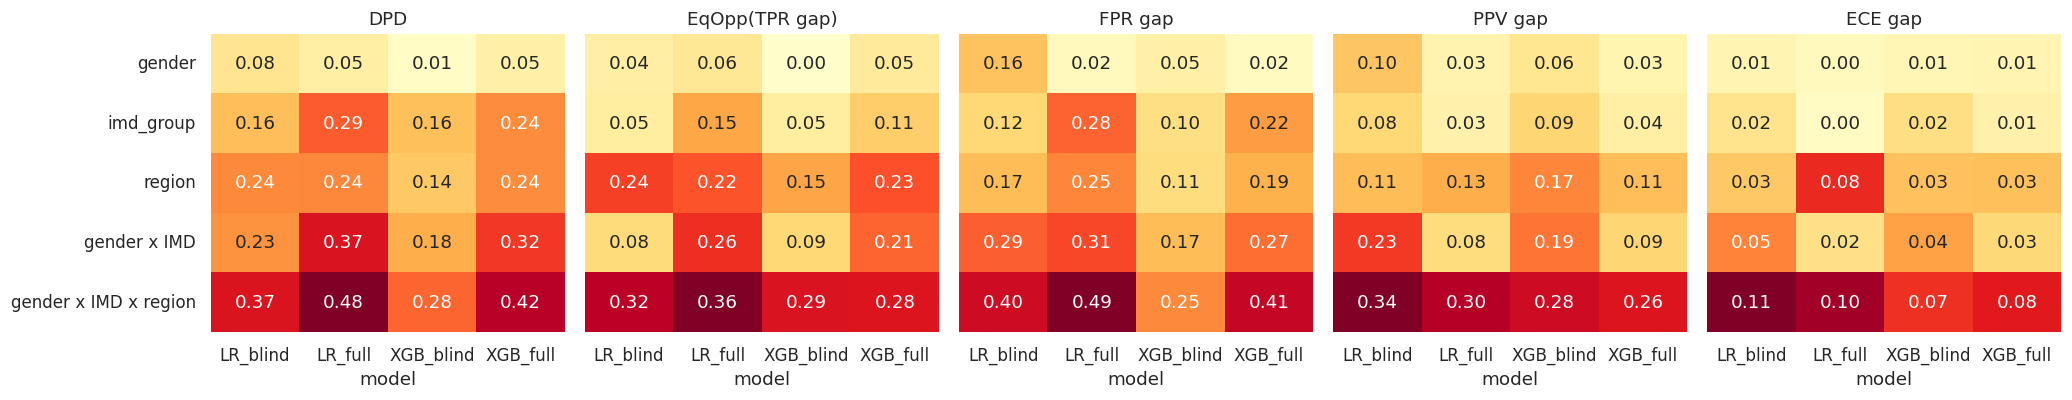

In [10]:
ATTRS = {"gender":"gender", "imd_group":"imd_group", "region":"region",
         "gender x IMD":"gender_x_imd", "gender x IMD x region":"gender_x_imd_x_region"}

def make_codes(series, y):
    s = pd.Series(series).astype(object).reset_index(drop=True); y = np.asarray(y)
    groups = []
    for g_, n in s.dropna().value_counts().items():
        m = (s == g_).values; pos = y[m].sum(); neg = m.sum() - pos
        if n >= MIN_GROUP_N and pos >= MIN_CLASS_N and neg >= MIN_CLASS_N: groups.append(g_)
    groups = sorted(groups); cmap = {g_: i for i, g_ in enumerate(groups)}
    codes = s.map(cmap).fillna(-1).astype(int).values
    return codes, groups

def _rng(a):
    a = np.asarray(a, float); a = a[np.isfinite(a)]
    return a.max() - a.min() if len(a) >= 2 else np.nan

def rates_from_codes(codes, y, yhat, K):
    m = codes >= 0; c, yy, hh = codes[m], y[m].astype(float), yhat[m].astype(float)
    n = np.bincount(c, minlength=K).astype(float); pos = np.bincount(c, weights=yy, minlength=K)
    flg = np.bincount(c, weights=hh, minlength=K); tp = np.bincount(c, weights=yy*hh, minlength=K)
    fp = flg - tp; neg = n - pos
    with np.errstate(divide="ignore", invalid="ignore"):
        return dict(n=n, pos=pos, base=pos/n, sel=flg/n, tpr=tp/pos, fpr=fp/neg, ppv=tp/flg)

def gaps_from_codes(codes, y, yhat, K):
    r = rates_from_codes(codes, y, yhat, K)
    d = {"DPD": _rng(r["sel"]), "EqOpp(TPR gap)": _rng(r["tpr"]), "FPR gap": _rng(r["fpr"]), "PPV gap": _rng(r["ppv"])}
    d["EqOdds"] = np.nanmax([d["EqOpp(TPR gap)"], d["FPR gap"]]) if np.isfinite([d["EqOpp(TPR gap)"], d["FPR gap"]]).any() else np.nan
    return d

def madd_scores(p, codes, K, bins=20):
    # histogram approximation of MADD (Verger et al. 2023): L1 distance between score densities, range [0,2]
    H = np.array([np.histogram(p[codes == k], bins=bins, range=(0,1))[0] / max((codes == k).sum(), 1) for k in range(K)])
    pair = [np.abs(H[i]-H[j]).sum() for i in range(K) for j in range(i+1, K)]
    vs_rest = []
    for k in range(K):
        rest = np.histogram(p[(codes != k) & (codes >= 0)], bins=bins, range=(0,1))[0] / max(((codes != k) & (codes >= 0)).sum(), 1)
        vs_rest.append(np.abs(H[k]-rest).sum())
    return (max(pair) if pair else np.nan), vs_rest

def group_table(T_, attr_col, name):
    codes, groups = make_codes(T_[attr_col].values, T_.y.values); K = len(groups)
    if K < 2: return None, None, codes, groups
    y_, yh, p_ = T_.y.values, T_[f"yhat_{name}"].values, T_[f"p_{name}"].values
    r = rates_from_codes(codes, y_, yh, K); mx, vs = madd_scores(p_, codes, K)
    gt = pd.DataFrame({"n": r["n"].astype(int), "base_rate": r["base"], "selection_rate": r["sel"], "TPR": r["tpr"],
                       "FPR": r["fpr"], "PPV": r["ppv"],
                       "ECE": [ece_score(y_[codes==k], p_[codes==k]) for k in range(K)],
                       "mean_p_minus_base": [p_[codes==k].mean() - y_[codes==k].mean() for k in range(K)],
                       "MADD_vs_rest": vs}, index=groups)
    gaps = gaps_from_codes(codes, y_, yh, K)
    gaps["ECE gap"] = _rng(gt["ECE"].values); gaps["MADD (max pair)"] = mx; gaps["n_groups"] = K
    return gt, gaps, codes, groups

# ---- headline audit across ALL models and attributes ----
audit_rows = []
for nm in MODELS:
    for an, col in ATTRS.items():
        gt, gaps, _, _ = group_table(T, col, nm)
        if gaps is not None: audit_rows.append({"model": nm, "attribute": an, **gaps})
audit = pd.DataFrame(audit_rows); save_table(audit.set_index(["model","attribute"]), "fairness_gaps_all_models")
display(audit.round(3))

metrics_to_plot = ["DPD","EqOpp(TPR gap)","FPR gap","PPV gap","ECE gap"]
fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(19, 3.8), sharey=True)
for ax, mname in zip(axes, metrics_to_plot):
    pv = audit.pivot(index="attribute", columns="model", values=mname).reindex(list(ATTRS.keys()))
    sns.heatmap(pv, annot=True, fmt=".2f", cmap="YlOrRd", cbar=False, ax=ax, vmin=0); ax.set_title(mname); ax.set_ylabel("")
save_fig("fairness_dashboard_heatmap"); plt.show()


=== XGB_full | gender ===


,n,base_rate,selection_rate,TPR,FPR,PPV,ECE,mean_p_minus_base,MADD_vs_rest
F,2938,0.505,0.546,0.775,0.312,0.717,0.016,0.005,0.176
M,3551,0.536,0.596,0.827,0.329,0.744,0.024,0.000,0.176



=== XGB_full | imd_group ===


,n,base_rate,selection_rate,TPR,FPR,PPV,ECE,mean_p_minus_base,MADD_vs_rest
IMD_High_Depr,2097,0.620,0.707,0.860,0.458,0.754,0.031,-0.017,0.374
IMD_Low_Depr,1682,0.444,0.467,0.755,0.238,0.716,0.031,0.018,0.313
IMD_Mid,2478,0.508,0.557,0.789,0.317,0.720,0.021,0.007,0.113



=== XGB_full | region ===


,n,base_rate,selection_rate,TPR,FPR,PPV,ECE,mean_p_minus_base,MADD_vs_rest
East Anglian Region,648,0.506,0.557,0.793,0.316,0.720,0.040,0.021,0.137
East Midlands Region,466,0.498,0.541,0.789,0.295,0.726,0.034,0.007,0.132
Ireland,233,0.455,0.416,0.623,0.244,0.680,0.061,-0.029,0.364
London Region,620,0.581,0.656,0.833,0.412,0.737,0.027,-0.001,0.223
North Region,371,0.458,0.504,0.771,0.279,0.701,0.059,0.030,0.230
North Western Region,558,0.608,0.634,0.811,0.361,0.777,0.045,-0.032,0.218
Scotland,684,0.480,0.591,0.823,0.376,0.668,0.048,0.035,0.198
South East Region,451,0.499,0.530,0.791,0.270,0.745,0.033,-0.000,0.209
South Region,647,0.495,0.502,0.784,0.226,0.772,0.029,-0.013,0.233
South West Region,471,0.471,0.512,0.770,0.281,0.710,0.027,0.018,0.197



=== XGB_full | gender x IMD ===


,n,base_rate,selection_rate,TPR,FPR,PPV,ECE,mean_p_minus_base,MADD_vs_rest
F|IMD_High_Depr,1027,0.609,0.698,0.838,0.480,0.731,0.035,-0.018,0.311
F|IMD_Low_Depr,678,0.404,0.392,0.668,0.205,0.688,0.038,0.023,0.423
F|IMD_Mid,1170,0.479,0.513,0.763,0.282,0.713,0.033,0.015,0.220
M|IMD_High_Depr,1070,0.631,0.716,0.880,0.435,0.775,0.045,-0.015,0.369
M|IMD_Low_Depr,1004,0.470,0.518,0.805,0.263,0.731,0.034,0.015,0.191
M|IMD_Mid,1308,0.534,0.596,0.810,0.351,0.726,0.019,-0.001,0.092


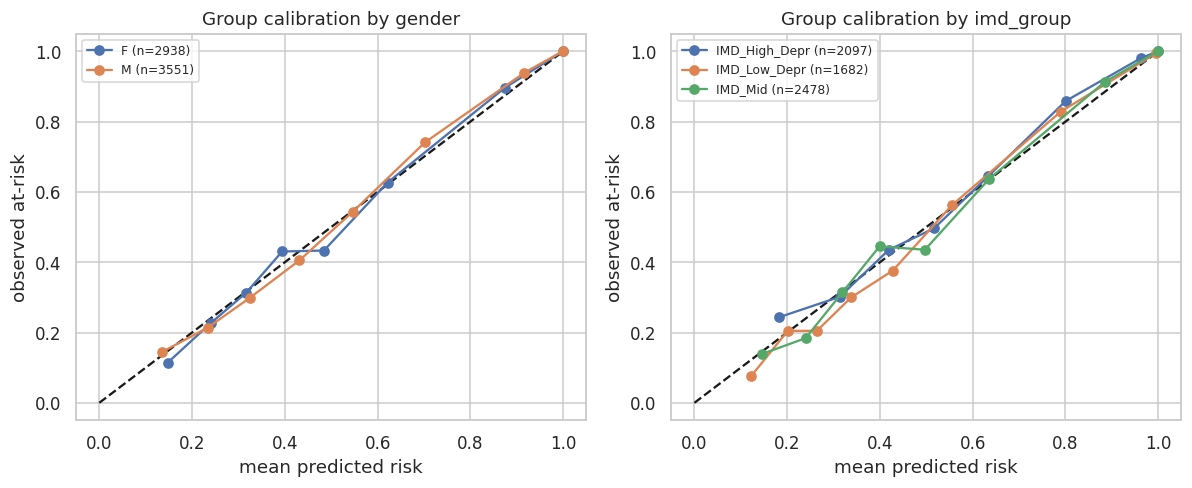

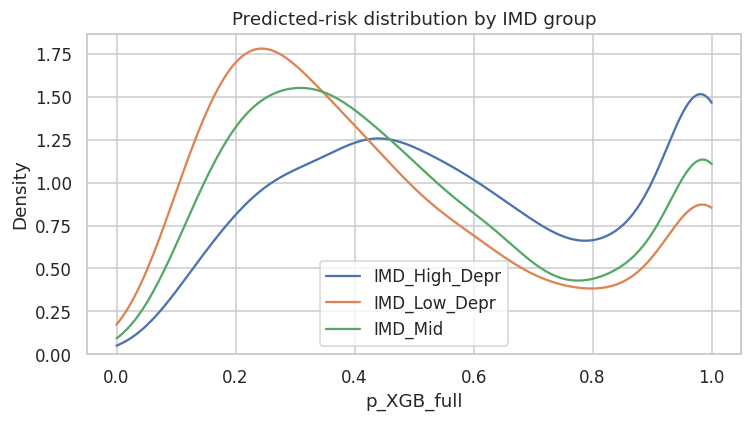

In [11]:
# ---- detailed per-group tables for the PRIMARY model ----
for an in ["gender","imd_group","region","gender x IMD"]:
    gt, gaps, _, _ = group_table(T, ATTRS[an], PRIMARY_MODEL)
    print(f"\n=== {PRIMARY_MODEL} | {an} ==="); display(save_table(gt.round(3), f"group_table_{PRIMARY_MODEL}_{an.replace(' ','_')}"))

# ---- group calibration curves ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, col in zip(axes, ["gender","imd_group"]):
    ax.plot([0,1],[0,1],"k--")
    for gname, sub in T.dropna(subset=[col]).groupby(col):
        if len(sub) < MIN_GROUP_N: continue
        fr, mp = calibration_curve(sub.y, sub[f"p_{PRIMARY_MODEL}"], n_bins=8, strategy="quantile"); ax.plot(mp, fr, marker="o", label=f"{gname} (n={len(sub)})")
    ax.set_title(f"Group calibration by {col}"); ax.set_xlabel("mean predicted risk"); ax.set_ylabel("observed at-risk"); ax.legend(fontsize=8)
save_fig("group_calibration"); plt.show()

# ---- score distributions (what MADD measures) ----
fig, ax = plt.subplots(figsize=(7,4))
for gname, sub in T.dropna(subset=["imd_group"]).groupby("imd_group"):
    sns.kdeplot(sub[f"p_{PRIMARY_MODEL}"], ax=ax, label=gname, clip=(0,1))
ax.set_title("Predicted-risk distribution by IMD group"); ax.legend(); save_fig("score_distribution_imd"); plt.show()

## 9. Stage 6: are the observed gaps statistically meaningful?
For the primary model:

* chi-square (and Fisher's exact test for two groups) on selection rates, with Cramér's V as the effect size
* **permutation tests** for the range of selection rate, TPR, FPR and PPV (labels shuffled within the relevant subset)
* **cluster-bootstrap 95% CIs** for each gap (students resampled)
* **group-vs-rest** tests (Fisher) with **Holm** correction across groups, including effect sizes with CIs

In [12]:
def perm_test(codes, values, subset, K, n_perm=N_PERM, seed=SEED):
    rng = np.random.default_rng(seed)
    c = codes[subset]; v = values[subset].astype(float); ok = c >= 0; c, v = c[ok], v[ok]
    cnt = np.bincount(c, minlength=K).astype(float); valid = cnt >= 5
    if valid.sum() < 2: return np.nan, np.nan
    obs_m = np.bincount(c, weights=v, minlength=K) / np.maximum(cnt, 1); obs = obs_m[valid].max() - obs_m[valid].min()
    hits = 0
    for _ in range(n_perm):
        pc = rng.permutation(c); mm = np.bincount(pc, weights=v, minlength=K) / np.maximum(cnt, 1)
        hits += (mm[valid].max() - mm[valid].min()) >= obs - 1e-12
    return obs, (hits + 1) / (n_perm + 1)

def chi2_selection(codes, yhat, K):
    ok = codes >= 0; tab = pd.crosstab(codes[ok], yhat[ok]).values
    if tab.shape[0] < 2 or tab.shape[1] < 2: return np.nan, np.nan, np.nan, np.nan
    chi2, p, dof, _ = stats.chi2_contingency(tab); V = np.sqrt(chi2 / (tab.sum() * (min(tab.shape) - 1)))
    pf = stats.fisher_exact(tab)[1] if tab.shape[0] == 2 else np.nan
    return chi2, p, V, pf

detail_rows = []
boot_T = ClusterBoot(T.id_student.values, seed=SEED+1)
for an, col in ATTRS.items():
    gt, gaps, codes, groups = group_table(T, col, PRIMARY_MODEL)
    if gaps is None: continue
    K = len(groups); y_, yh = T.y.values, T[f"yhat_{PRIMARY_MODEL}"].values
    chi2, pchi, V, pfish = chi2_selection(codes, yh, K)
    _, p_sel = perm_test(codes, yh, np.ones(len(yh), bool), K)
    _, p_tpr = perm_test(codes, yh, y_ == 1, K)
    _, p_fpr = perm_test(codes, yh, y_ == 0, K)
    _, p_ppv = perm_test(codes, y_, yh == 1, K)
    bs = pd.DataFrame([gaps_from_codes(codes[i], y_[i], yh[i], K) for i in [boot_T.sample() for _ in range(N_BOOT)]])
    row = {"attribute": an, "K": K, "chi2_p(selection)": pchi, "CramersV": V, "Fisher_p(2 groups)": pfish,
           "perm_p DPD": p_sel, "perm_p TPR gap": p_tpr, "perm_p FPR gap": p_fpr, "perm_p PPV gap": p_ppv}
    for k in ["DPD","EqOpp(TPR gap)","FPR gap","EqOdds","PPV gap"]:
        lo, hi = bs[k].quantile([.025,.975]); row[f"{k} [95% CI]"] = f"{gaps[k]:.3f} [{lo:.3f},{hi:.3f}]"
    detail_rows.append(row)
detail = pd.DataFrame(detail_rows).set_index("attribute"); save_table(detail, f"significance_{PRIMARY_MODEL}")
display(detail.round(4).T)
print("Note: bootstrap range-gaps are biased upward for small groups (max-min of noisy estimates), so read them next to the permutation p-values and effect sizes.")

attribute,gender,imd_group,region,gender x IMD,gender x IMD x region
K,2,3,13,6,27
chi2_p(selection),0.0001,0.0,0.0,0.0,0.0
CramersV,0.0503,0.1928,0.1284,0.2105,0.234
Fisher_p(2 groups),0.0,NaN,NaN,NaN,NaN
perm_p DPD,0.0005,0.0005,0.0005,0.0005,0.0005
perm_p TPR gap,0.001,0.0005,0.001,0.0005,0.0215
perm_p FPR gap,0.3048,0.0005,0.007,0.0005,0.0045
perm_p PPV gap,0.075,0.1154,0.2424,0.0235,0.1144
DPD [95% CI],"0.050 [0.027,0.074]","0.240 [0.209,0.272]","0.240 [0.188,0.332]","0.324 [0.278,0.375]","0.420 [0.375,0.560]"
EqOpp(TPR gap) [95% CI],"0.052 [0.024,0.078]","0.105 [0.075,0.137]","0.228 [0.162,0.345]","0.212 [0.155,0.270]","0.283 [0.280,0.478]"


Note: bootstrap range-gaps are biased upward for small groups (max-min of noisy estimates), so read them next to the permutation p-values and effect sizes.


In [13]:
# ---- group-vs-rest tests with Holm correction ----
def group_vs_rest(T_, col, name):
    codes, groups = make_codes(T_[col].values, T_.y.values); y_, yh = T_.y.values, T_[f"yhat_{name}"].values
    rows = []
    if len(groups) < 2: return None
    for k, g_ in enumerate(groups):
        ing, rest = codes == k, (codes >= 0) & (codes != k)
        # selection rate
        a, n1, c_, n0 = yh[ing].sum(), ing.sum(), yh[rest].sum(), rest.sum()
        p_sel = stats.fisher_exact([[a, n1-a],[c_, n0-c_]])[1]; lo, hi = confint_proportions_2indep(a, n1, c_, n0, method="newcomb")
        # TPR
        ip, rp = ing & (y_==1), rest & (y_==1)
        a2, n12, c2, n02 = yh[ip].sum(), ip.sum(), yh[rp].sum(), rp.sum()
        p_tpr = stats.fisher_exact([[a2, n12-a2],[c2, n02-c2]])[1]; lo2, hi2 = confint_proportions_2indep(a2, n12, c2, n02, method="newcomb")
        rows.append({"group": g_, "n": n1, "sel_diff": a/n1 - c_/n0, "sel_CI": f"[{lo:.3f},{hi:.3f}]", "p_sel": p_sel,
                     "TPR_diff": a2/n12 - c2/n02, "TPR_CI": f"[{lo2:.3f},{hi2:.3f}]", "p_tpr": p_tpr})
    out = pd.DataFrame(rows).set_index("group")
    out["p_sel_holm"] = multipletests(out.p_sel, method="holm")[1]; out["p_tpr_holm"] = multipletests(out.p_tpr, method="holm")[1]
    return out

for an in ["region","gender x IMD","gender x IMD x region"]:
    r = group_vs_rest(T, ATTRS[an], PRIMARY_MODEL)
    if r is None: print(f"\n=== {an}: fewer than 2 eligible groups (lower MIN_GROUP_N to see more) ==="); continue
    save_table(r, f"group_vs_rest_{an.replace(' ','_')}")
    print(f"\n=== {an}: group vs rest ({PRIMARY_MODEL}); Holm-adjusted over {len(r)} groups ===")
    display(r.sort_values("p_tpr_holm").head(12).round(4))


=== region: group vs rest (XGB_full); Holm-adjusted over 13 groups ===


,n,sel_diff,sel_CI,p_sel,TPR_diff,TPR_CI,p_tpr,p_sel_holm,p_tpr_holm
group,,,,,,,,,
Ireland,233,-0.1627,"[-0.225,-0.097]",0.0000,-0.1875,"[-0.283,-0.100]",0.0000,0.0000,0.0001
West Midlands Region,546,0.0861,"[0.043,0.127]",0.0001,0.0508,"[0.006,0.088]",0.0278,0.0011,0.3331
East Midlands Region,466,-0.0349,"[-0.082,0.012]",0.1450,-0.0166,"[-0.075,0.033]",0.5485,0.4351,1.0000
East Anglian Region,648,-0.0178,"[-0.058,0.022]",0.4025,-0.0128,"[-0.062,0.030]",0.5590,0.6945,1.0000
North Region,371,-0.0733,"[-0.125,-0.021]",0.0058,-0.0354,"[-0.105,0.023]",0.2748,0.0463,1.0000
North Western Region,558,0.0671,"[0.024,0.108]",0.0023,0.0077,"[-0.039,0.048]",0.7732,0.0208,1.0000
Scotland,684,0.0196,"[-0.020,0.058]",0.3473,0.0209,"[-0.026,0.061]",0.3806,0.6945,1.0000
London Region,620,0.0921,"[0.052,0.131]",0.0000,0.0325,"[-0.012,0.070]",0.1597,0.0001,1.0000
South East Region,451,-0.0464,"[-0.094,0.001]",0.0607,-0.0141,"[-0.073,0.036]",0.6022,0.3033,1.0000



=== gender x IMD: group vs rest (XGB_full); Holm-adjusted over 6 groups ===


,n,sel_diff,sel_CI,p_sel,TPR_diff,TPR_CI,p_tpr,p_sel_holm,p_tpr_holm
group,,,,,,,,,
F|IMD_Low_Depr,678,-0.2141,"[-0.252,-0.175]",0.0000,-0.1540,"[-0.213,-0.099]",0.0000,0.0000,0.0000
M|IMD_High_Depr,1070,0.1601,"[0.129,0.190]",0.0000,0.0890,"[0.058,0.117]",0.0000,0.0000,0.0000
F|IMD_Mid,1170,-0.0866,"[-0.118,-0.055]",0.0000,-0.0557,"[-0.095,-0.019]",0.0026,0.0000,0.0106
F|IMD_High_Depr,1027,0.1375,"[0.106,0.168]",0.0000,0.0361,"[0.002,0.067]",0.0418,0.0000,0.1253
M|IMD_Low_Depr,1004,-0.0777,"[-0.111,-0.044]",0.0000,-0.0047,"[-0.045,0.032]",0.8005,0.0000,1.0000
M|IMD_Mid,1308,0.0166,"[-0.014,0.046]",0.2838,0.0008,"[-0.033,0.032]",1.0000,0.2838,1.0000



=== gender x IMD x region: group vs rest (XGB_full); Holm-adjusted over 27 groups ===


,n,sel_diff,sel_CI,p_sel,TPR_diff,TPR_CI,p_tpr,p_sel_holm,p_tpr_holm
group,,,,,,,,,
F|IMD_Low_Depr|South Region,135,-0.2596,"[-0.336,-0.175]",0.0000,-0.1886,"[-0.321,-0.072]",0.0015,0.0000,0.0400
F|IMD_Low_Depr|East Anglian Region,108,-0.2078,"[-0.296,-0.112]",0.0000,-0.1820,"[-0.327,-0.056]",0.0039,0.0006,0.1020
M|IMD_Mid|South West Region,129,-0.1219,"[-0.208,-0.035]",0.0062,-0.1334,"[-0.265,-0.024]",0.0233,0.1178,0.5829
M|IMD_Mid|East Midlands Region,103,-0.1180,"[-0.213,-0.021]",0.0191,-0.1375,"[-0.283,-0.019]",0.0345,0.2863,0.8273
M|IMD_High_Depr|Scotland,109,0.1389,"[0.047,0.216]",0.0039,0.1033,"[0.007,0.156]",0.0369,0.0787,0.8492
M|IMD_Mid|East Anglian Region,146,0.0416,"[-0.041,0.118]",0.3447,0.0947,"[0.007,0.147]",0.0400,1.0000,0.8791
M|IMD_High_Depr|North Western Region,166,0.1583,"[0.085,0.221]",0.0000,0.0823,"[0.005,0.134]",0.0406,0.0011,0.8791
F|IMD_High_Depr|West Midlands Region,112,0.1189,"[0.027,0.197]",0.0143,0.0510,"[-0.051,0.117]",0.3538,0.2284,1.0000
F|IMD_Mid|Scotland,122,-0.0850,"[-0.174,0.004]",0.0746,-0.0992,"[-0.235,0.008]",0.0762,0.8949,1.0000


## 10. Why a single "fair" label is impossible: incompatibility of criteria + Simpson's check on model decisions
When base rates differ between groups, **independence, separation and sufficiency cannot all hold** (Barocas-Hardt-Narayanan; Chouldechova 2017). The identity

`FPR = (p / (1-p)) · ((1-PPV) / PPV) · TPR`  (p = group base rate)

shows that if two groups have different base rates, equal PPV and equal TPR force *different* FPRs. The table checks the identity on the actual predictions and prints what FPR *would have to be* for a group if it matched the reference group's TPR and PPV.

In [14]:
def incompat_table(col, ref):
    gt, gaps, codes, groups = group_table(T, col, PRIMARY_MODEL)
    tb = gt[["n","base_rate","TPR","FPR","PPV"]].copy()
    p_ = tb.base_rate
    tb["FPR_implied_by_identity"] = (p_/(1-p_)) * ((1-tb.PPV)/tb.PPV) * tb.TPR
    tb["identity_error"] = (tb.FPR - tb.FPR_implied_by_identity).abs()
    if ref in tb.index:
        r = tb.loc[ref]
        tb["FPR_if_TPR&PPV_match_ref"] = (p_/(1-p_)) * ((1-r.PPV)/r.PPV) * r.TPR
    return tb.round(4)
for col, ref in [("gender","M"), ("imd_group","IMD_Low_Depr")]:
    print(f"\n=== {col} (reference = {ref}) ==="); display(save_table(incompat_table(col, ref), f"incompatibility_{col}"))

# ---- Simpson's paradox on the MODEL decisions (test set; within module) ----
rows = []
for gcol, comp, ref in [("gender","F","M"), ("imd_group","IMD_High_Depr","IMD_Low_Depr")]:
    for outcome, label in [("y","observed at-risk"), (f"yhat_{PRIMARY_MODEL}","model flag")]:
        o, _ = simpson_table(T, gcol, outcome, comp, ref, "code_module")
        rows.append({"group": f"{comp} vs {ref}", "outcome": label, **o})
sim_m = pd.DataFrame(rows); save_table(sim_m, "simpson_model_flags"); display(sim_m.round(3))


=== gender (reference = M) ===


,n,base_rate,TPR,FPR,PPV,FPR_implied_by_identity,identity_error,FPR_if_TPR&PPV_match_ref
F,2938,0.5051,0.7749,0.3116,0.7174,0.3116,0.0,0.2907
M,3551,0.5359,0.8271,0.3289,0.7439,0.3289,0.0,0.3289



=== imd_group (reference = IMD_Low_Depr) ===


,n,base_rate,TPR,FPR,PPV,FPR_implied_by_identity,identity_error,FPR_if_TPR&PPV_match_ref
IMD_High_Depr,2097,0.6199,0.8600,0.4580,0.7539,0.4580,0.0,0.4876
IMD_Low_Depr,1682,0.4435,0.7547,0.2382,0.7163,0.2382,0.0,0.2382
IMD_Mid,2478,0.5085,0.7889,0.3169,0.7203,0.3169,0.0,0.3092


,group,outcome,pooled_rd,n_strata,within_rd_mean(weighted),n_strata_sign_differs_from_pooled,MH_common_OR,paradox_flag
0,F vs M,observed at-risk,-0.031,7,-0.043,1,0.837,False
1,F vs M,model flag,-0.050,7,-0.130,0,0.581,False
2,IMD_High_Depr vs IMD_Low_Depr,observed at-risk,0.176,7,0.176,0,2.064,False
3,IMD_High_Depr vs IMD_Low_Depr,model flag,0.240,7,0.240,0,2.774,False


## 11. Stage 7: structural causal model, identification and adjusted effects (Objective 3)

**Proposed SCM (a causal *hypothesis*, not something discovered from OULAD).**

* Sensitive context **A** = {gender, IMD, region} (+ age band as a background covariate)
* **W** module chosen by the student (A → W): module composition is what creates Simpson's paradox
* **B** prior academic profile (education, previous attempts, credits, registration lead)
* **E** early engagement (VLE clicks, active days, assessments)
* **U** *unobserved* background (internet access, work, caring duties) → B, E, Y
* **R** model risk score (B, E, W → R); dotted **A → R** = direct use of sensitive attributes by the model
* **D** support decision (R → D); **Y** final at-risk outcome

Backdoor sets are found by **d-separation** (never adjusting for descendants of the exposure, i.e. mediators/colliders). The front-door criterion is checked programmatically. All estimates are *assumption-dependent*.

,exposure,outcome,minimal backdoor sets,descendants (never adjust)
0,imd,Y,[[region]],"[B, D, E, R, W, Y]"
1,imd,R,[[region]],"[B, D, E, R, W, Y]"
2,gender,Y,[[{} (empty set)]],"[B, D, E, R, W, Y]"
3,gender,R,[[{} (empty set)]],"[B, D, E, R, W, Y]"
4,region,Y,[[{} (empty set)]],"[B, D, E, R, W, Y, imd]"
5,region,R,[[{} (empty set)]],"[B, D, E, R, W, Y, imd]"


,exposure,mediators M,adjust Z,(i) M intercepts all paths,(ii) no open backdoor x->M,(iii) M->Y backdoors blocked by x,front-door OK
0,imd,"(E,)",(),False,False,False,False
1,imd,"(E,)","(region,)",False,True,False,False
2,imd,"(B, E)",(),False,False,False,False
3,imd,"(B, E)","(region,)",False,True,False,False
4,imd,"(W, B, E)",(),True,False,False,False
5,imd,"(W, B, E)","(region,)",True,True,False,False
6,gender,"(E,)",(),False,True,False,False
7,gender,"(B, E)",(),False,True,False,False
8,gender,"(W, B, E)",(),True,True,False,False


Front-door criterion is NOT satisfied for any candidate: the unobserved U confounds mediators and outcome (iii), and W/direct paths bypass M (i).


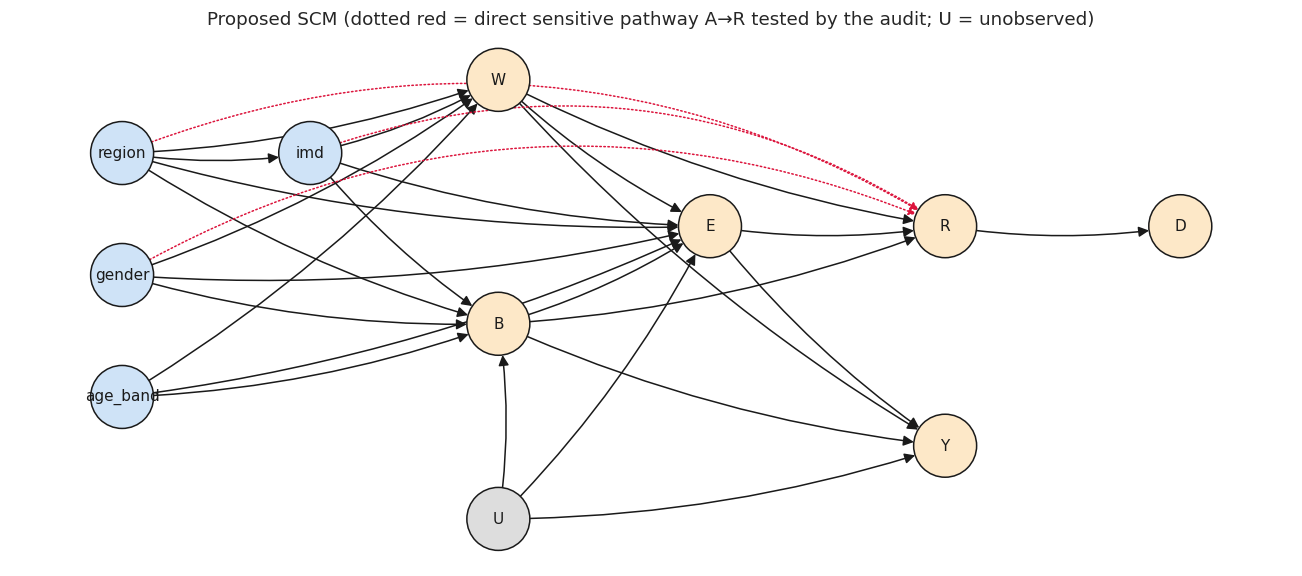

In [15]:
G = nx.DiGraph()
edges = [("region","imd"),("region","W"),("region","B"),("region","E"),
         ("gender","W"),("gender","B"),("gender","E"),
         ("age_band","W"),("age_band","B"),("age_band","E"),
         ("imd","W"),("imd","B"),("imd","E"),
         ("W","E"),("W","Y"),("W","R"),
         ("B","E"),("U","B"),("U","E"),("U","Y"),
         ("B","R"),("E","R"),("B","Y"),("E","Y"),("R","D")]
direct = [("gender","R"),("region","R"),("imd","R")]      # model uses sensitive attrs directly (dotted)
G.add_edges_from(edges + direct)
assert nx.is_directed_acyclic_graph(G)
OBSERVED = ["gender","age_band","region","imd","W","B","E","R"]      # U is unobserved

def d_sep(Gx, X, Y, Z):
    X, Y, Z = set(X), set(Y), set(Z)
    return nx.is_d_separator(Gx, X, Y, Z) if hasattr(nx, "is_d_separator") else nx.d_separated(Gx, X, Y, Z)

def backdoor_sets(Gx, x, y, observed):
    desc = nx.descendants(Gx, x)
    cand = [v for v in observed if v not in desc and v not in (x, y)]          # never adjust for descendants of x
    Gb = Gx.copy(); Gb.remove_edges_from(list(Gx.out_edges(x)))                 # keep only backdoor paths
    valid = [set(Z) for k in range(len(cand)+1) for Z in itertools.combinations(cand, k) if d_sep(Gb, {x}, {y}, set(Z))]
    return [z for z in valid if not any(o < z for o in valid)], desc

def check_front_door(Gx, x, y, M, Z=()):
    M, Z = set(M), set(Z)
    G_noM = Gx.copy(); G_noM.remove_nodes_from(M)
    c1 = not (x in G_noM and y in G_noM and nx.has_path(G_noM, x, y))            # M intercepts all directed x -> y paths
    Gb = Gx.copy(); Gb.remove_edges_from(list(Gx.out_edges(x)))
    c2 = d_sep(Gb, {x}, M, Z)                                                    # no open backdoor x -> M (given Z)
    Gm = Gx.copy(); Gm.remove_edges_from([e for m in M for e in list(Gx.out_edges(m))])
    c3 = d_sep(Gm, M, {y}, {x} | Z)                                              # backdoors M -> y blocked by x (and Z)
    return c1, c2, c3

bd_rows = []
for x in ["imd","gender","region"]:
    for y in ["Y","R"]:
        sets, desc = backdoor_sets(G, x, y, OBSERVED)
        bd_rows.append({"exposure": x, "outcome": y, "minimal backdoor sets": [sorted(s) or ["{}  (empty set)"] for s in sets],
                        "descendants (never adjust)": sorted(desc)})
display(pd.DataFrame(bd_rows))

fd_rows = []
for x in ["imd","gender"]:
    for M in [("E",), ("B","E"), ("W","B","E")]:
        for Z in [(), ("region",)] if x == "imd" else [()]:
            c1, c2, c3 = check_front_door(G, x, "Y", M, Z)
            fd_rows.append({"exposure": x, "mediators M": M, "adjust Z": Z, "(i) M intercepts all paths": c1,
                            "(ii) no open backdoor x->M": c2, "(iii) M->Y backdoors blocked by x": c3, "front-door OK": c1 and c2 and c3})
fd = pd.DataFrame(fd_rows); display(fd)
print("Front-door criterion is NOT satisfied for any candidate: the unobserved U confounds mediators and outcome (iii), and W/direct paths bypass M (i).")

# ---- draw the DAG ----
pos = {"region":(0,3),"gender":(0,2),"age_band":(0,1),"imd":(1.6,3),"W":(3.2,3.6),"B":(3.2,1.6),"U":(3.2,0.0),
       "E":(5,2.4),"R":(7,2.4),"Y":(7,0.6),"D":(9,2.4)}
fig, ax = plt.subplots(figsize=(12,5.4))
nx.draw_networkx_nodes(G, pos, node_size=1700, node_color=["#ddd" if n=="U" else "#cfe3f7" if n in ("region","gender","age_band","imd") else "#fde8c8" for n in G.nodes], edgecolors="k", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=edges, arrows=True, arrowsize=14, node_size=1700, ax=ax, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edges(G, pos, edgelist=direct, arrows=True, style="dotted", edge_color="crimson", node_size=1700, ax=ax, connectionstyle="arc3,rad=-0.25")
ax.set_title("Proposed SCM (dotted red = direct sensitive pathway A→R tested by the audit; U = unobserved)"); ax.axis("off")
save_fig("scm_dag"); plt.show()

,exposure,outcome,strategy,adjusts for,risk_diff,RD_lo,RD_hi,RR,RR_lo,RR_hi
0,IMD: high vs low deprivation,observed at-risk (Y),unadjusted,nothing,0.160,0.147,0.173,1.349,1.316,1.385
1,IMD: high vs low deprivation,observed at-risk (Y),backdoor set (total effect),region,0.145,0.130,0.160,1.310,1.274,1.349
2,IMD: high vs low deprivation,observed at-risk (Y),backdoor + module (within-module),region+W,0.147,0.133,0.162,1.316,1.279,1.355
3,IMD: high vs low deprivation,observed at-risk (Y),over-adjusted: + B + E (mediators),region+W+B+E,0.081,0.068,0.095,1.160,1.134,1.193
4,IMD: high vs low deprivation,model risk score (R) [test only],unadjusted,nothing,0.141,0.124,0.162,1.306,1.263,1.359
5,IMD: high vs low deprivation,model risk score (R) [test only],backdoor set (total effect),region,0.126,0.106,0.146,1.269,1.218,1.320
6,IMD: high vs low deprivation,model risk score (R) [test only],backdoor + module (within-module),region+W,0.125,0.103,0.146,1.265,1.211,1.317
7,IMD: high vs low deprivation,model risk score (R) [test only],over-adjusted: + B + E (mediators),region+W+B+E,0.066,0.055,0.077,1.131,1.109,1.155
8,Gender: female vs male,observed at-risk (Y),unadjusted,nothing,-0.022,-0.033,-0.011,0.958,0.939,0.980
9,Gender: female vs male,observed at-risk (Y),backdoor set (total effect),nothing,-0.022,-0.033,-0.011,0.958,0.939,0.980


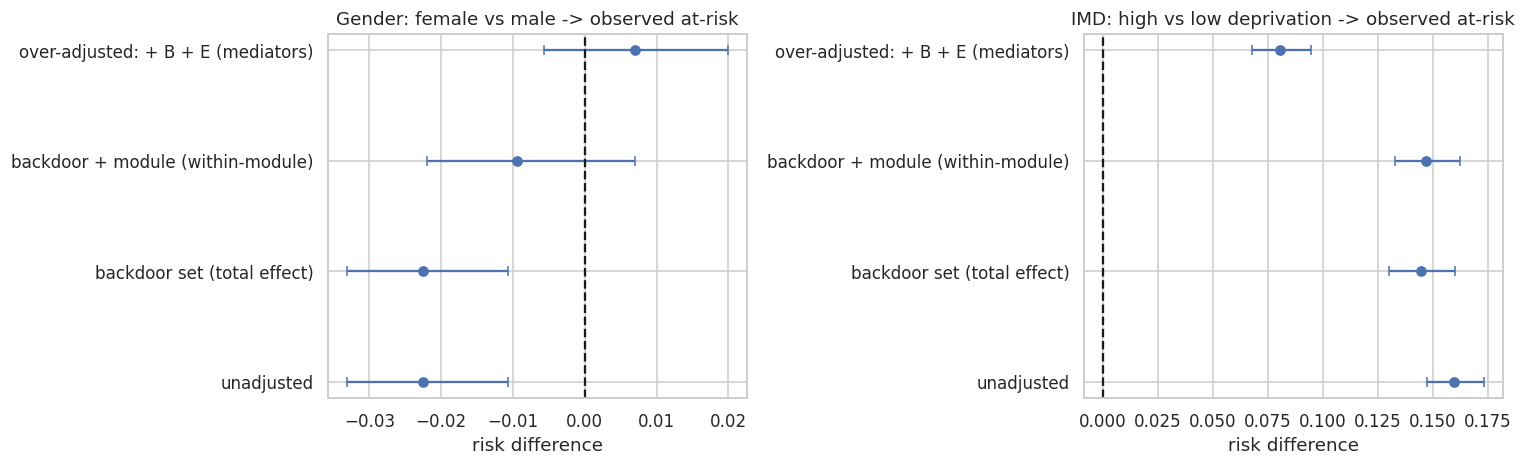

,exposure,RR,RR 95% CI,E-value (point),E-value (CI limit)
0,Gender: female vs male,0.958,"[0.94,0.98]",1.257,1.165
1,IMD: high vs low deprivation,1.310,"[1.27,1.35]",1.948,1.865


E-value = minimum strength of association an unmeasured confounder would need with BOTH exposure and outcome to fully explain away the estimate.
Interpretation: the 'backdoor' row is the defensible total-effect estimate under the DAG; the 'over-adjusted' row conditions on mediators (and U-induced collider/confounding bias) and must not be read as a causal direct effect.


In [16]:
# ---------- adjusted effect estimates (g-computation, cluster-bootstrap CIs) ----------
B_VARS = ["highest_education_ord","num_of_prev_attempts","studied_credits","reg_lead_days"]
E_VARS = ["log_total_clicks","active_days","unique_activity_types","submitted_assessments","late_submissions","mean_score"]
NODE_COLS = {"region":["region"], "gender":["gender_F"], "age_band":["age_ord"], "W":["code_module"],
             "B":B_VARS, "E":[v for v in E_VARS if v != "mean_score"]}

def build_X(d, expo, nodes):
    parts = [d[[expo]].astype(float)]
    for nd in nodes:
        for c in NODE_COLS[nd]:
            if not pd.api.types.is_numeric_dtype(d[c]): parts.append(pd.get_dummies(d[c], prefix=c, drop_first=True).astype(float))
            else: parts.append(((d[[c]] - d[c].mean()) / (d[c].std() + 1e-9)).astype(float))
    return sm.add_constant(pd.concat(parts, axis=1), has_constant="add")

def gcomp(X, y, kind, idx=None):
    Xv, yv = (X.values, y) if idx is None else (X.values[idx], y[idx]); j = list(X.columns).index("expo")
    mod = sm.GLM(yv, Xv, family=sm.families.Binomial()) if kind == "logit" else sm.OLS(yv, Xv)
    r = mod.fit(); X1, X0 = Xv.copy(), Xv.copy(); X1[:, j] = 1; X0[:, j] = 0
    p1, p0 = r.predict(X1).mean(), r.predict(X0).mean()
    return p1 - p0, (p1 / p0 if p0 > 0 else np.nan)

def estimate(d, outcome, kind, nodes, label, n_boot=N_BOOT_CAUSAL, seed=SEED):
    d = d.reset_index(drop=True); X = build_X(d, "expo", nodes); y = d[outcome].values.astype(float)
    rd, rr = gcomp(X, y, kind); cb = ClusterBoot(d.id_student.values, seed=seed); bs = []
    for _ in range(n_boot):
        try: bs.append(gcomp(X, y, kind, cb.sample()))
        except Exception: pass
    bs = np.array(bs); lo, hi = np.nanpercentile(bs[:,0], [2.5, 97.5]); rlo, rhi = np.nanpercentile(bs[:,1], [2.5, 97.5])
    return {"strategy": label, "adjusts for": "+".join(nodes) or "nothing", "risk_diff": rd, "RD_lo": lo, "RD_hi": hi, "RR": rr, "RR_lo": rlo, "RR_hi": rhi}

def evalue(rr, lo, hi):
    f = lambda r: np.nan if not np.isfinite(r) else (r + np.sqrt(r*(r-1)) if r >= 1 else (1/r) + np.sqrt((1/r)*((1/r)-1)))
    ci_bound = lo if rr >= 1 else hi
    ci_e = 1.0 if (lo <= 1 <= hi) else f(ci_bound)
    return f(rr), ci_e

# analysis frames
dfc = df.copy()
dfc["pR"] = np.nan; dfc.loc[T.index, "pR"] = RESULTS[PRIMARY_MODEL]["p"]        # model risk score exists on test rows
EXPOSURES = {"IMD: high vs low deprivation": ("imd", dfc[dfc.imd_group.isin(["IMD_High_Depr","IMD_Low_Depr"])].assign(expo=lambda d: (d.imd_group=="IMD_High_Depr").astype(int))),
             "Gender: female vs male":       ("gender", dfc.assign(expo=lambda d: (d.gender=="F").astype(int)))}
eff_rows = []
for en, (xnode, dd) in EXPOSURES.items():
    bd = backdoor_sets(G, xnode, "Y", OBSERVED)[0][0]; bd = sorted(bd)
    strategies = [("unadjusted", []), ("backdoor set (total effect)", bd), ("backdoor + module (within-module)", bd + ["W"]),
                  ("over-adjusted: + B + E (mediators)", bd + ["W","B","E"])]
    for outcome, kind, dsub, ol in [("y","logit",dd,"observed at-risk (Y)"), ("pR","linear",dd[dd.pR.notna()],f"model risk score (R) [test only]")]:
        for lab, nodes in strategies:
            r = estimate(dsub, outcome, kind, nodes, lab); r.update({"exposure": en, "outcome": ol}); eff_rows.append(r)
eff = pd.DataFrame(eff_rows)[["exposure","outcome","strategy","adjusts for","risk_diff","RD_lo","RD_hi","RR","RR_lo","RR_hi"]]
save_table(eff.set_index(["exposure","outcome","strategy"]), "causal_effect_estimates"); display(eff.round(3))

# forest plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=False)
for ax, (en, grp) in zip(axes, eff[eff.outcome.str.startswith("observed")].groupby("exposure")):
    ax.errorbar(grp.risk_diff, range(len(grp)), xerr=[grp.risk_diff-grp.RD_lo, grp.RD_hi-grp.risk_diff], fmt="o", capsize=3)
    ax.set_yticks(range(len(grp))); ax.set_yticklabels(grp.strategy); ax.axvline(0, c="k", ls="--"); ax.set_title(en + " -> observed at-risk"); ax.set_xlabel("risk difference")
save_fig("causal_forest"); plt.show()

# E-values for the backdoor-adjusted total effect on observed outcome
ev = []
for en, grp in eff[(eff.outcome.str.startswith("observed")) & (eff.strategy.str.startswith("backdoor set"))].groupby("exposure"):
    r = grp.iloc[0]; e_pt, e_ci = evalue(r.RR, r.RR_lo, r.RR_hi)
    ev.append({"exposure": en, "RR": r.RR, "RR 95% CI": f"[{r.RR_lo:.2f},{r.RR_hi:.2f}]", "E-value (point)": e_pt, "E-value (CI limit)": e_ci})
display(pd.DataFrame(ev).round(3))
print("E-value = minimum strength of association an unmeasured confounder would need with BOTH exposure and outcome to fully explain away the estimate.")
print("Interpretation: the 'backdoor' row is the defensible total-effect estimate under the DAG; the 'over-adjusted' row conditions on mediators (and U-induced collider/confounding bias) and must not be read as a causal direct effect.")

## 12. Stage 8: counterfactual sensitivity analysis
For each test student the SCM is used with the classic **abduction → action → prediction** steps:

1. *Abduction:* fit structural equations on the training set for B-variables (parents: gender, IMD, age, region, module) and E-variables (parents additionally include B); compute each student's exogenous **residual**.
2. *Action:* intervene on the sensitive attribute (IMD ±3 deciles / to least deprived, gender flip, region change).
3. *Prediction:* recompute **descendants only**, in topological order (B then E), keeping residuals and non-descendants fixed (discrete variables are rounded back to integers); derived features (total clicks, clicks/day, education label) are recomputed; then re-score with the trained model.

The change is decomposed into **direct** (model sees changed A, descendants fixed), **indirect** (A fixed, descendants changed) and **total**. These are *fairness stress tests of the model*, not claims that a student's real circumstances could change independently.

identity check LR_full: max |p_cf - p_obs| = 4.84e-02
identity check XGB_full: max |p_cf - p_obs| = 2.87e-02


,model,scenario,path,mean_dRisk,CI_lo,CI_hi,pct_flag_added,pct_flag_removed,pct_decision_changed
0,LR_full,IMD +3 deciles (less deprived),total,-0.036,-0.037,-0.035,0.000,6.872,6.872
1,LR_full,IMD +3 deciles (less deprived),direct (A only),-0.023,-0.023,-0.022,0.000,4.267,4.267
2,LR_full,IMD +3 deciles (less deprived),indirect (descendants only),-0.014,-0.014,-0.013,0.000,2.477,2.477
3,XGB_full,IMD +3 deciles (less deprived),total,-0.032,-0.032,-0.031,0.096,6.728,6.824
4,XGB_full,IMD +3 deciles (less deprived),direct (A only),-0.016,-0.017,-0.016,0.128,3.612,3.740
5,XGB_full,IMD +3 deciles (less deprived),indirect (descendants only),-0.015,-0.016,-0.015,0.080,3.069,3.148
6,LR_blind,IMD +3 deciles (less deprived),total,-0.014,-0.014,-0.014,0.000,2.701,2.701
7,LR_blind,IMD +3 deciles (less deprived),direct (A only),0.000,0.000,0.000,0.000,0.000,0.000
8,LR_blind,IMD +3 deciles (less deprived),indirect (descendants only),-0.014,-0.014,-0.014,0.000,2.701,2.701
9,XGB_blind,IMD +3 deciles (less deprived),total,-0.016,-0.016,-0.015,0.384,3.756,4.139


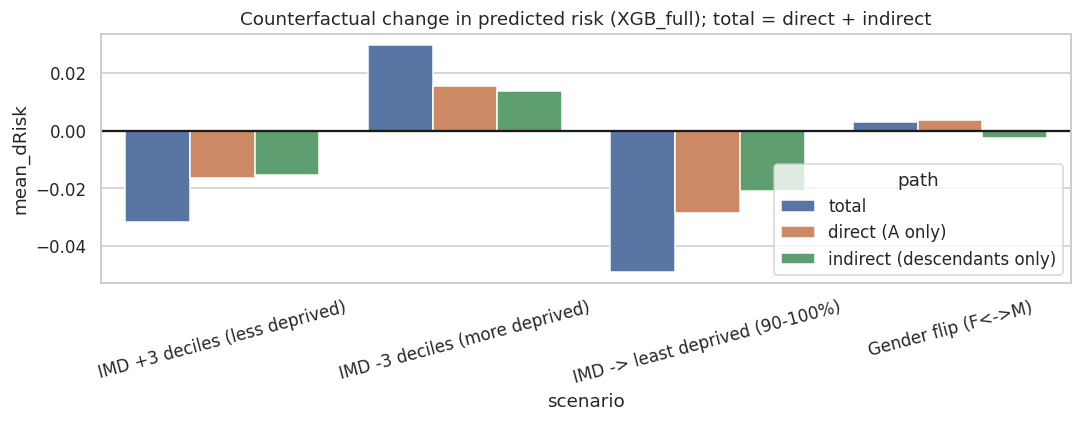

In [17]:
class SCM:
    def __init__(self, spec="ols"): self.spec = spec
    def _A(self, d):
        X = pd.DataFrame({"gender_F": d.gender_F.astype(float), "imd_ord": d.imd_ord.astype(float), "age_ord": d.age_ord.astype(float)}, index=d.index)
        R = pd.get_dummies(pd.Categorical(d.region, categories=self.regions), prefix="reg", drop_first=True).astype(float); R.index = d.index
        M = pd.get_dummies(pd.Categorical(d.code_module, categories=self.modules), prefix="mod", drop_first=True).astype(float); M.index = d.index
        return pd.concat([X, R, M], axis=1)
    def design(self, d, v):
        X = self._A(d)
        return pd.concat([X, d[B_VARS].astype(float)], axis=1) if v in E_VARS else X
    def fit(self, d):
        d = d[d.imd_ord.notna()]; self.regions = sorted(df.region.unique()); self.modules = sorted(df.code_module.unique())
        self.m, self.lo, self.hi = {}, {}, {}
        for v in B_VARS + E_VARS:
            sub = d[d[v].notna()]
            est = LinearRegression() if self.spec == "ols" else HistGradientBoostingRegressor(max_iter=150, max_depth=4, random_state=SEED)
            est.fit(self.design(sub, v), sub[v]); self.m[v] = est; self.lo[v], self.hi[v] = sub[v].min(), sub[v].max()
        return self
    def predict(self, d, v): return pd.Series(self.m[v].predict(self.design(d, v)), index=d.index)

def derive(d):
    d = d.copy()
    d["total_clicks"] = np.round(np.expm1(d["log_total_clicks"]))                           # clicks are whole numbers
    d["clicks_per_active_day"] = np.where(d["active_days"] > 0, d["total_clicks"] / d["active_days"].clip(lower=1), 0.0)
    d["highest_education"] = d["highest_education_ord"].round().clip(0, 4).astype(int).map(EDU_INV)
    d["imd_band"] = d["imd_ord"].round().clip(0, 9).astype(int).map(lambda k: IMD_LABELS[k])
    return d

INT_VARS = ["highest_education_ord","num_of_prev_attempts","studied_credits","reg_lead_days",
            "active_days","unique_activity_types","submitted_assessments","late_submissions"]   # discrete variables stay integer-valued

def scm_counterfactual(scm, d, intervene):
    d0 = d.copy(); resid = {v: d0[v] - scm.predict(d0, v) for v in B_VARS + E_VARS}          # abduction
    d1 = intervene(d0.copy())                                                                  # action
    for v in B_VARS + E_VARS:                                                                  # prediction (B first, then E)
        d1[v] = (scm.predict(d1, v) + resid[v]).clip(lower=scm.lo[v], upper=scm.hi[v])
        if v in INT_VARS: d1[v] = d1[v].round()   # tree models split exactly at integers: fractional counts would create artefactual flips
    return derive(d1)

def set_imd(d, ordv):
    d["imd_ord"] = np.clip(np.round(ordv), 0, 9); d["imd_group"] = pd.cut(d["imd_ord"], bins=[-1,2,6,9], labels=["IMD_High_Depr","IMD_Mid","IMD_Low_Depr"]).astype(object); return d
def flip_gender(d):
    d["gender"] = np.where(d["gender"] == "F", "M", "F"); d["gender_F"] = 1.0 - d["gender_F"]; return d
def set_region(d, r): d["region"] = r; return d

SCENARIOS = {"IMD +3 deciles (less deprived)": lambda d: set_imd(d, d.imd_ord + 3),
             "IMD -3 deciles (more deprived)": lambda d: set_imd(d, d.imd_ord - 3),
             "IMD -> least deprived (90-100%)": lambda d: set_imd(d, np.full(len(d), 9.0)),
             "Gender flip (F<->M)": flip_gender}
A_MODEL = ["gender","region","imd_band"]

scm_ols = SCM("ols").fit(train)
Tc = derive(T[T.imd_ord.notna()].copy())
# sanity: identity intervention must reproduce the observed predictions
Tid = scm_counterfactual(scm_ols, Tc, lambda d: d)
for nm in ["LR_full","XGB_full"]:
    print(f"identity check {nm}: max |p_cf - p_obs| = {np.abs(predict_p(MODELS[nm], Tid) - predict_p(MODELS[nm], Tc)).max():.2e}")

cb_cf = ClusterBoot(Tc.id_student.values, seed=SEED+7); cf_idx = [cb_cf.sample() for _ in range(N_BOOT_CAUSAL)]

def cf_effects(model_name, d_obs, d_cf, scenario):
    M = MODELS[model_name]; thr = M["thr"]; p0 = predict_p(M, d_obs); out = []
    d_dir = d_obs.copy(); d_dir[A_MODEL] = d_cf[A_MODEL].values
    d_ind = d_cf.copy();  d_ind[A_MODEL] = d_obs[A_MODEL].values
    for path, dd in [("total", d_cf), ("direct (A only)", d_dir), ("indirect (descendants only)", d_ind)]:
        p1 = predict_p(M, dd); dl = p1 - p0; bs = [dl[i].mean() for i in cf_idx]; lo, hi = np.percentile(bs, [2.5, 97.5])
        out.append({"model": model_name, "scenario": scenario, "path": path, "mean_dRisk": dl.mean(), "CI_lo": lo, "CI_hi": hi,
                    "pct_flag_added": ((p0 < thr) & (p1 >= thr)).mean()*100, "pct_flag_removed": ((p0 >= thr) & (p1 < thr)).mean()*100,
                    "pct_decision_changed": (((p0 >= thr) != (p1 >= thr))).mean()*100})
    return out

def run_cf(model_names, scm):
    rows = []
    for sc, fn in SCENARIOS.items():
        d_cf = scm_counterfactual(scm, Tc, fn)
        for nm in model_names: rows += cf_effects(nm, Tc, d_cf, sc)
    return pd.DataFrame(rows)

cf_main = run_cf(["LR_full","XGB_full","LR_blind","XGB_blind"], scm_ols)
save_table(cf_main.set_index(["model","scenario","path"]), "counterfactual_main"); display(cf_main.round(3))

# decomposition plot for the primary model
sub = cf_main[(cf_main.model == PRIMARY_MODEL)]
fig, ax = plt.subplots(figsize=(10, 4)); sns.barplot(data=sub, x="scenario", y="mean_dRisk", hue="path", ax=ax)
ax.axhline(0, c="k"); ax.set_title(f"Counterfactual change in predicted risk ({PRIMARY_MODEL}); total = direct + indirect"); plt.xticks(rotation=15)
save_fig("counterfactual_decomposition"); plt.show()

In [18]:
# ---- sensitivity to the SCM specification (linear vs gradient-boosted structural equations) ----
scm_gbr = SCM("gbr").fit(train)
spec_rows = []
for spec_name, scm in [("OLS structural eqs", scm_ols), ("GBR structural eqs", scm_gbr)]:
    for sc, fn in SCENARIOS.items():
        d_cf = scm_counterfactual(scm, Tc, fn)
        r = [x for x in cf_effects(PRIMARY_MODEL, Tc, d_cf, sc) if x["path"] == "total"][0]; r["SCM spec"] = spec_name; spec_rows.append(r)
spec = pd.DataFrame(spec_rows)[["SCM spec","scenario","mean_dRisk","CI_lo","CI_hi","pct_decision_changed"]]
save_table(spec.set_index(["SCM spec","scenario"]), "counterfactual_spec_sensitivity"); display(spec.round(3))

# ---- region counterfactual: set everyone to each region ----
reg_rows = []
for r_ in sorted(df.region.unique()):
    d_cf = scm_counterfactual(scm_ols, Tc, lambda d, r_=r_: set_region(d, r_))
    p0, p1 = predict_p(MODELS[PRIMARY_MODEL], Tc), predict_p(MODELS[PRIMARY_MODEL], d_cf)
    reg_rows.append({"region set to": r_, "mean_dRisk": (p1-p0).mean(), "pct_decision_changed": ((p0>=MODELS[PRIMARY_MODEL]['thr'])!=(p1>=MODELS[PRIMARY_MODEL]['thr'])).mean()*100})
reg_cf = pd.DataFrame(reg_rows).set_index("region set to").sort_values("mean_dRisk"); save_table(reg_cf, "counterfactual_region"); display(reg_cf.round(3))
print("Counterfactual caveat: IMD and region describe *where a student lives*; these results are model stress tests, not predictions of what would happen if a real student's circumstances changed.")

,SCM spec,scenario,mean_dRisk,CI_lo,CI_hi,pct_decision_changed
0,OLS structural eqs,IMD +3 deciles (less deprived),-0.032,-0.032,-0.031,6.824
1,OLS structural eqs,IMD -3 deciles (more deprived),0.030,0.029,0.031,6.585
2,OLS structural eqs,IMD -> least deprived (90-100%),-0.049,-0.050,-0.048,10.580
3,OLS structural eqs,Gender flip (F<->M),0.003,0.001,0.005,12.562
4,GBR structural eqs,IMD +3 deciles (less deprived),-0.027,-0.028,-0.026,6.057
5,GBR structural eqs,IMD -3 deciles (more deprived),0.026,0.025,0.027,6.217
6,GBR structural eqs,IMD -> least deprived (90-100%),-0.046,-0.047,-0.045,10.197
7,GBR structural eqs,Gender flip (F<->M),0.003,0.001,0.004,10.996


,mean_dRisk,pct_decision_changed
region set to,,
Ireland,-0.046,9.973
South East Region,-0.021,5.658
South Region,-0.019,6.057
South West Region,-0.013,4.891
West Midlands Region,-0.008,4.171
East Midlands Region,0.000,4.091
Yorkshire Region,0.003,4.091
East Anglian Region,0.005,4.203
North Western Region,0.008,4.155


Counterfactual caveat: IMD and region describe *where a student lives*; these results are model stress tests, not predictions of what would happen if a real student's circumstances changed.


## 13. Stage 9: fairness mitigation (Objective 4)
All mitigation is fitted on **train (+ validation for thresholds)** only; the locked test set is untouched until the final comparison.

* **Reweighing** (Kamiran-Calders): weights `w(s,y) = P(s)P(y)/P(s,y)` on the attribute `MITIGATION_ATTR`, then LR / XGBoost retrained; threshold re-chosen on validation with the same recall-target rule.
* **Fairlearn `ExponentiatedGradient`** (in-processing reduction) with a pre-specified constraint (`MITIGATION_CONSTRAINT`). For a *support* use case where the harm is *missing* an at-risk student, **equalised odds / equal opportunity** is the more natural default than demographic parity; switch in the config to compare.
* **`ThresholdOptimizer`** (post-processing, optional, as in the OULAD literature).

All variants are re-audited on the same test set, so accuracy, recall, false alarms, calibration and every fairness metric are compared side by side.

In [19]:
feats_m = FEATS_FULL if MITIGATION_FEATURES == "full" else FEATS_BLIND
S_train = train[MITIGATION_ATTR].fillna("Unknown").astype(str)

def reweighing_weights(s, y):
    d = pd.DataFrame({"s": np.asarray(s), "y": np.asarray(y)}); n = len(d)
    ps = d.s.map(d.s.value_counts() / n); py = d.y.map(d.y.value_counts() / n)
    pj = d.groupby(["s","y"]).s.transform("size") / n
    return (ps * py / pj).values
w_rw = reweighing_weights(S_train, train.y)
print("Reweighing weights: min %.2f, max %.2f" % (w_rw.min(), w_rw.max()))

# ---- 1) Reweighing ----
for kind in ["LR","XGB"]:
    nm = f"{kind}_reweigh"; MODELS[nm] = train_model(kind, feats_m, nm, w_train=w_rw)
    p = predict_p(MODELS[nm], T); register(nm, p, (p >= MODELS[nm]["thr"]).astype(int), MODELS[nm]["thr"])

# ---- 2) ExponentiatedGradient (in-processing) ----
pre_m = make_preprocessor(feats_m).fit(train[feats_m]); Xtr_m = pre_m.transform(train[feats_m]); Xte_m = pre_m.transform(T[feats_m])
C_m = MODELS[f"LR_{MITIGATION_FEATURES}"]["params"]["C"]
cons = EqualizedOdds() if MITIGATION_CONSTRAINT == "EqualizedOdds" else DemographicParity()
eg = ExponentiatedGradient(LogisticRegression(C=C_m, max_iter=3000), constraints=cons, eps=EG_EPS)
eg.fit(Xtr_m, train.y.values, sensitive_features=S_train.values)
p_eg = eg._pmf_predict(Xte_m)[:, 1]; yhat_eg = np.asarray(eg.predict(Xte_m, random_state=SEED)).astype(int)
register("LR_ExpGrad", p_eg, yhat_eg, None)
print("ExponentiatedGradient: %d base predictors in the randomised ensemble" % int((eg.weights_ > 0).sum()))

# ---- 3) ThresholdOptimizer (optional post-processing) ----
try:
    from fairlearn.postprocessing import ThresholdOptimizer
    from sklearn.base import BaseEstimator, ClassifierMixin
    class Float64Proba(BaseEstimator, ClassifierMixin):          # XGBoost returns float32; fairlearn needs float64
        def __init__(self, base=None): self.base = base; self.classes_ = np.array([0, 1])
        def fit(self, X, y=None): return self
        def predict_proba(self, X): return np.asarray(self.base.predict_proba(X), dtype="float64")
        def predict(self, X): return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)
    base_nm = PRIMARY_MODEL; Mb = MODELS[base_nm]
    pre_b, clf_b = Mb["pipe"].named_steps["pre"], Mb["pipe"].named_steps["clf"]      # numeric matrix avoids dtype issues
    to = ThresholdOptimizer(estimator=Float64Proba(clf_b), constraints="equalized_odds", objective="balanced_accuracy_score",
                            prefit=True, predict_method="predict_proba")
    to.fit(pre_b.transform(val[Mb["feats"]]), val.y.values, sensitive_features=val[MITIGATION_ATTR].fillna("Unknown").astype(str).values)
    yhat_to = np.asarray(to.predict(pre_b.transform(T[Mb["feats"]]), sensitive_features=T[MITIGATION_ATTR].fillna("Unknown").astype(str).values, random_state=SEED)).astype(int)
    register(f"{base_nm}_threshopt", RESULTS[base_nm]["p"], yhat_to, None)
except Exception as e:
    print("ThresholdOptimizer skipped:", repr(e)[:200])
print("Registered models:", list(RESULTS))

Reweighing weights: min 0.72, max 1.52
ExponentiatedGradient: 4 base predictors in the randomised ensemble
Registered models: ['LR_full', 'LR_blind', 'XGB_full', 'XGB_blind', 'LR_reweigh', 'XGB_reweigh', 'LR_ExpGrad', 'XGB_full_threshopt']


,BalAcc,Precision,Recall,F1,ROC_AUC,PR_AUC,Brier,ECE,Flag_rate,DPD_gen,...,PPVgap_imd,ECEgap_imd,DPD_reg,EqOdds_reg,PPVgap_reg,ECEgap_reg,DPD_g×imd,EqOdds_g×imd,PPVgap_g×imd,ECEgap_g×imd
model,,,,,,,,,,,,,,,,,,,,,
LR_full,0.726,0.715,0.802,0.756,0.829,0.867,0.166,0.013,0.585,0.054,...,0.032,0.003,0.244,0.252,0.130,0.075,0.375,0.314,0.076,0.021
LR_blind,0.722,0.711,0.798,0.752,0.823,0.862,0.168,0.013,0.586,0.085,...,0.085,0.019,0.242,0.240,0.114,0.032,0.228,0.289,0.227,0.055
XGB_full,0.742,0.732,0.804,0.767,0.845,0.880,0.158,0.014,0.573,0.050,...,0.038,0.010,0.240,0.228,0.113,0.035,0.324,0.275,0.087,0.026
XGB_blind,0.739,0.729,0.805,0.765,0.842,0.878,0.159,0.012,0.576,0.010,...,0.088,0.023,0.144,0.152,0.173,0.034,0.184,0.168,0.185,0.045
LR_reweigh,0.723,0.709,0.807,0.755,0.823,0.863,0.168,0.021,0.594,0.072,...,0.134,0.040,0.182,0.196,0.164,0.048,0.184,0.125,0.173,0.043
XGB_reweigh,0.735,0.724,0.804,0.762,0.841,0.878,0.159,0.014,0.580,0.075,...,0.116,0.029,0.164,0.168,0.165,0.050,0.212,0.128,0.164,0.039
LR_ExpGrad,0.742,0.783,0.693,0.736,0.764,0.737,0.252,0.251,0.462,0.067,...,0.110,0.026,0.230,0.288,0.153,0.098,0.174,0.126,0.168,0.067
XGB_full_threshopt,0.698,0.813,0.528,0.640,0.845,0.880,0.158,0.014,0.339,0.057,...,0.097,0.010,0.127,0.146,0.177,0.035,0.130,0.131,0.149,0.026


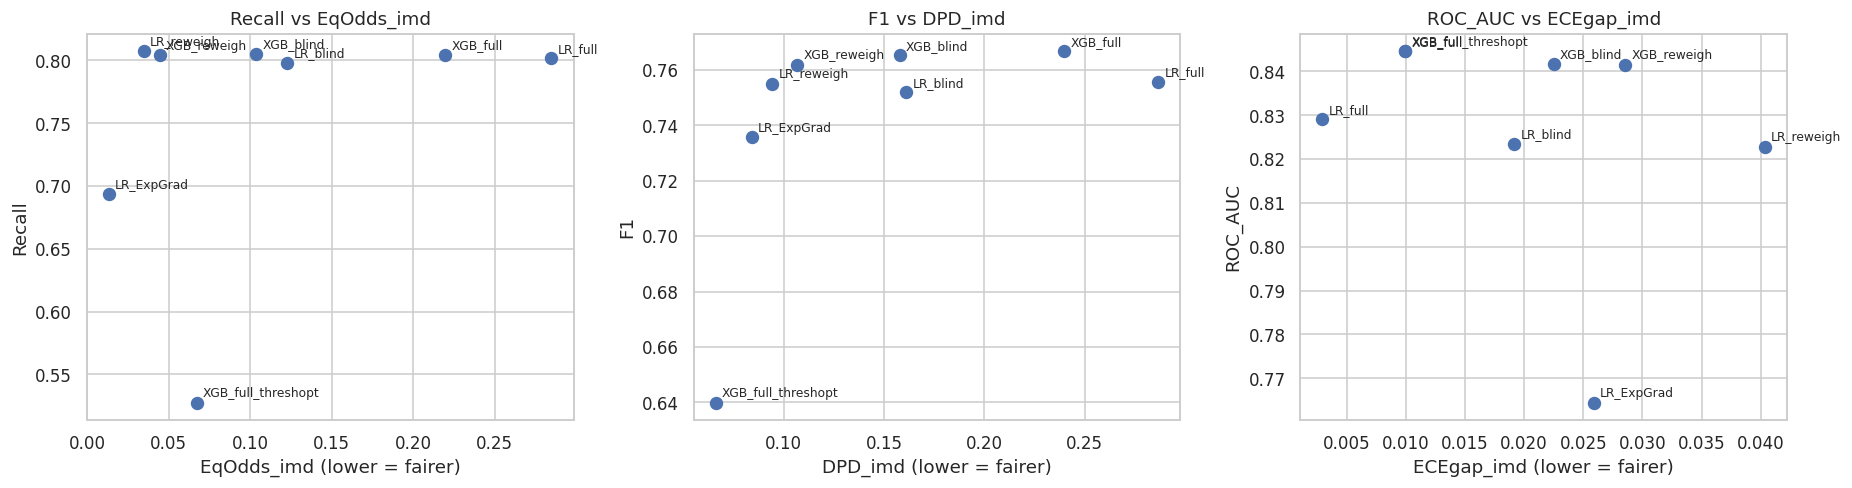

,model,scenario,path,mean_dRisk,CI_lo,CI_hi,pct_flag_added,pct_flag_removed,pct_decision_changed
0,LR_reweigh,IMD +3 deciles (less deprived),total,-0.006,-0.007,-0.006,0.591,2.078,2.669
3,XGB_reweigh,IMD +3 deciles (less deprived),total,-0.013,-0.014,-0.012,0.559,3.500,4.059
6,LR_reweigh,IMD -3 deciles (more deprived),total,0.007,0.006,0.007,1.982,0.559,2.541
9,XGB_reweigh,IMD -3 deciles (more deprived),total,0.011,0.011,0.012,3.420,0.671,4.091
12,LR_reweigh,IMD -> least deprived (90-100%),total,-0.014,-0.015,-0.014,0.064,3.452,3.516
15,XGB_reweigh,IMD -> least deprived (90-100%),total,-0.021,-0.021,-0.020,0.304,4.811,5.114
18,LR_reweigh,Gender flip (F<->M),total,-0.005,-0.008,-0.002,8.614,9.941,18.555
21,XGB_reweigh,Gender flip (F<->M),total,0.003,0.001,0.006,7.911,6.808,14.720


In [20]:
# ---- final side-by-side comparison on the locked test set ----
comp_rows = []
for nm, r in RESULTS.items():
    row = {"model": nm, **{k: v for k, v in perf(yT, r["p"], r["thr"] or 0.5, yhat=r["yhat"]).items()}}
    for an in ["gender","imd_group","region","gender x IMD"]:
        gt, gaps, _, _ = group_table(T, ATTRS[an], nm)
        if gaps is None: continue
        short = {"gender":"gen","imd_group":"imd","region":"reg","gender x IMD":"g×imd"}[an]
        row[f"DPD_{short}"] = gaps["DPD"]; row[f"EqOdds_{short}"] = gaps["EqOdds"]; row[f"PPVgap_{short}"] = gaps["PPV gap"]; row[f"ECEgap_{short}"] = gaps["ECE gap"]
    comp_rows.append(row)
comp = pd.DataFrame(comp_rows).set_index("model"); save_table(comp, "mitigation_comparison")
display(comp.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (xcol, ycol) in zip(axes, [("EqOdds_imd","Recall"), ("DPD_imd","F1"), ("ECEgap_imd","ROC_AUC")]):
    ax.scatter(comp[xcol], comp[ycol], s=60)
    for nm_, r_ in comp.iterrows(): ax.annotate(nm_, (r_[xcol], r_[ycol]), fontsize=8, xytext=(4,4), textcoords="offset points")
    ax.set_xlabel(xcol + " (lower = fairer)"); ax.set_ylabel(ycol); ax.set_title(f"{ycol} vs {xcol}")
save_fig("mitigation_tradeoff"); plt.show()

# ---- counterfactual stress test of the reweighed pipelines ----
cf_rw = run_cf(["LR_reweigh","XGB_reweigh"], scm_ols); display(cf_rw[cf_rw.path=="total"].round(3))

## 14. Stage 10: explainability and subgroup error analysis
Logistic-regression coefficients and SHAP summaries describe **what the model uses**, not what *causes* risk. They are used to spot **proxy features** and to give reviewers a reason code, never as causal evidence.

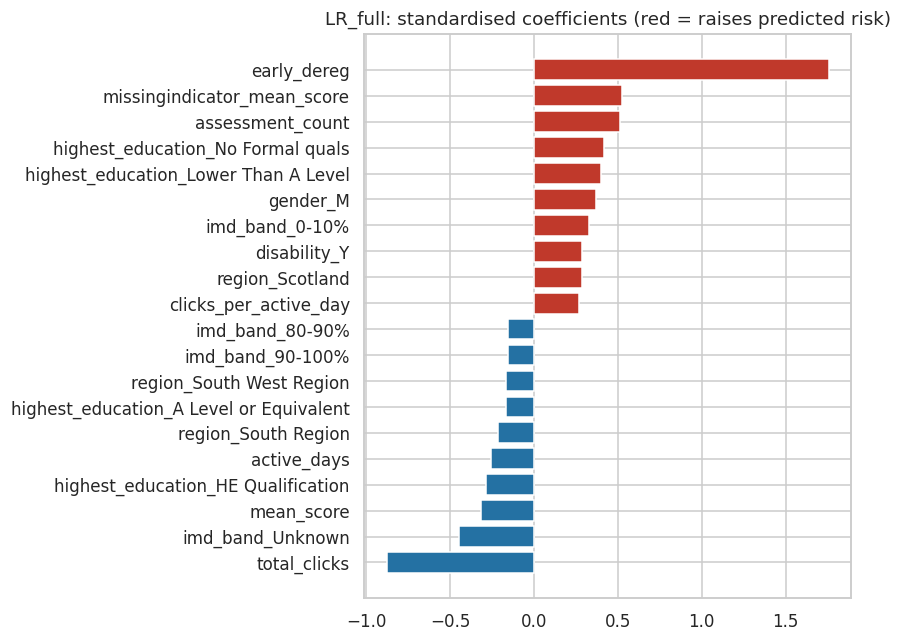

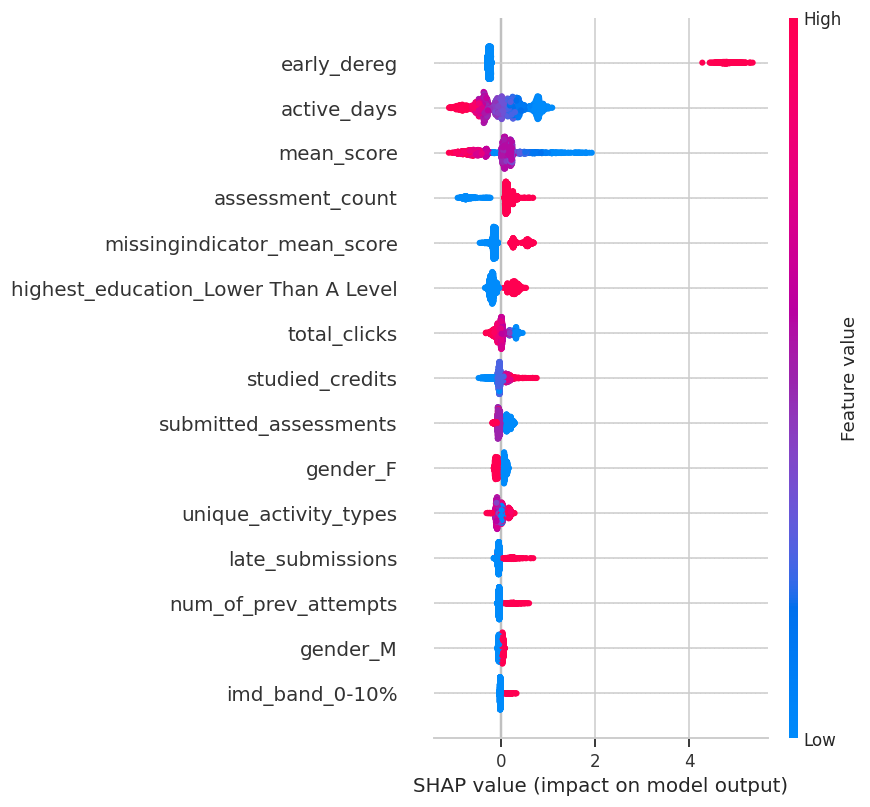

Share of total mean|SHAP| carried by direct sensitive features (gender/region/IMD): 11.4%


,mean|SHAP|
early_dereg,0.9337
active_days,0.4003
mean_score,0.3457
assessment_count,0.2526
missingindicator_mean_score,0.2518
highest_education_Lower Than A Level,0.2176
total_clicks,0.1088
studied_credits,0.1072
submitted_assessments,0.0981
gender_F,0.0891


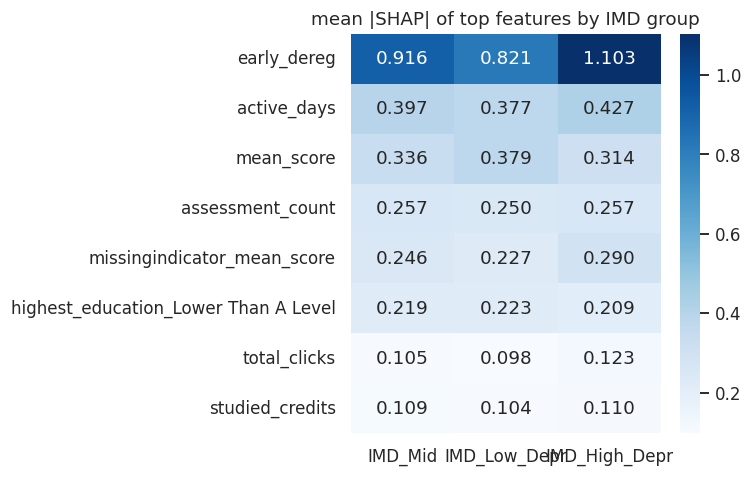

,original,boot1,boot2,boot3
original,1.000,0.953,0.963,0.948
boot1,0.953,1.000,0.913,0.903
boot2,0.963,0.913,1.000,0.953
boot3,0.948,0.903,0.953,1.000


Spearman rank correlation of global feature importance across refits (closer to 1 = more stable explanations).

Missed at-risk students (false negatives) by IMD group - XGB_full


,FNR,n_at_risk
imd_group,,
IMD_High_Depr,0.140,1300
IMD_Low_Depr,0.245,746
IMD_Mid,0.211,1260


Profile of missed vs caught at-risk students:


,false negatives,true positives
total_clicks,435.03,130.33
active_days,17.93,6.76
submitted_assessments,0.98,0.54
mean_score,79.54,60.62
reg_lead_days,66.81,73.87


,false negatives,true positives
total_clicks,435.034691,130.334435
active_days,17.930618,6.763583
submitted_assessments,0.981900,0.539280
mean_score,79.539020,60.615287
reg_lead_days,66.806938,73.867107


In [21]:
# ---- LR coefficients ----
M = MODELS["LR_full"]; names = M["pipe"].named_steps["pre"].get_feature_names_out(); coef = M["pipe"].named_steps["clf"].coef_.ravel()
cdf = pd.Series(coef, index=names).sort_values(); top = pd.concat([cdf.head(10), cdf.tail(10)])
fig, ax = plt.subplots(figsize=(8, 6)); ax.barh(top.index, top.values, color=np.where(top.values > 0, "#c0392b", "#2471a3"))
ax.set_title("LR_full: standardised coefficients (red = raises predicted risk)"); save_fig("lr_coefficients"); plt.show()
save_table(cdf.rename("coef").to_frame(), "lr_coefficients")

# ---- SHAP for the tree model ----
XM = MODELS["XGB_full"]; pre_x = XM["pipe"].named_steps["pre"]; clf_x = XM["pipe"].named_steps["clf"]
fn = list(pre_x.get_feature_names_out())
samp = T.sample(min(2000, len(T)), random_state=SEED); X_s = pre_x.transform(samp[XM["feats"]])
sv = shap.TreeExplainer(clf_x).shap_values(X_s)
sv = sv[1] if isinstance(sv, list) else sv
plt.figure(); shap.summary_plot(sv, X_s, feature_names=fn, max_display=15, show=False); save_fig("shap_summary"); plt.show()

imp = pd.Series(np.abs(sv).mean(0), index=fn).sort_values(ascending=False)
sens_mask = [any(f.startswith(p) for p in ("gender_","region_","imd_band_")) for f in imp.index]
print("Share of total mean|SHAP| carried by direct sensitive features (gender/region/IMD): %.1f%%" % (100 * imp[sens_mask].sum() / imp.sum()))
display(imp.head(12).round(4).to_frame("mean|SHAP|"))

# ---- do features matter differently by group? (proxy hunting) ----
gcol = "imd_group"; top_f = list(imp.head(8).index); gm = samp[gcol].values
gs = pd.DataFrame({g_: np.abs(sv[gm == g_][:, [fn.index(f) for f in top_f]]).mean(0) for g_ in pd.unique(gm[pd.notna(gm)])}, index=top_f)
fig, ax = plt.subplots(figsize=(7, 4.5)); sns.heatmap(gs, annot=True, fmt=".3f", cmap="Blues", ax=ax); ax.set_title("mean |SHAP| of top features by IMD group")
save_fig("shap_by_group"); plt.show()

# ---- stability of explanations across student-level bootstrap refits ----
Xtr_x = pre_x.transform(train[XM["feats"]]); ytr_x = train.y.values; cbs = ClusterBoot(train.id_student.values, seed=SEED+3); imps = {"original": imp.reindex(fn)}
X_small = X_s[:1000]
for b in range(N_STABILITY):
    ii = cbs.sample(); c_b = XGBClassifier(**XM["params"], eval_metric="logloss", tree_method="hist", random_state=SEED+b, n_jobs=-1).fit(Xtr_x[ii], ytr_x[ii])
    s_b = shap.TreeExplainer(c_b).shap_values(X_small); s_b = s_b[1] if isinstance(s_b, list) else s_b
    imps[f"boot{b+1}"] = pd.Series(np.abs(s_b).mean(0), index=fn)
stab = pd.DataFrame(imps).corr(method="spearman"); display(stab.round(3)); save_table(stab, "shap_stability")
print("Spearman rank correlation of global feature importance across refits (closer to 1 = more stable explanations).")

# ---- subgroup error analysis: who is being missed? ----
pm_ = PRIMARY_MODEL; fnmask = (T.y == 1) & (T[f"yhat_{pm_}"] == 0); tpmask = (T.y == 1) & (T[f"yhat_{pm_}"] == 1)
fnr = T[T.y == 1].assign(missed=lambda d: (d[f"yhat_{pm_}"] == 0)).groupby("imd_group").missed.agg(["mean","size"]).rename(columns={"mean":"FNR","size":"n_at_risk"})
print(f"\nMissed at-risk students (false negatives) by IMD group - {pm_}"); display(fnr.round(3))
prof = T.loc[fnmask, ["total_clicks","active_days","submitted_assessments","mean_score","reg_lead_days"]].mean().to_frame("false negatives").join(
       T.loc[tpmask, ["total_clicks","active_days","submitted_assessments","mean_score","reg_lead_days"]].mean().to_frame("true positives"))
print("Profile of missed vs caught at-risk students:"); display(prof.round(2)); save_table(prof, "fn_vs_tp_profile")

## 15. Human-review recommendations and limits (to adapt in the report)

**Supportive, not punitive use.** A flag triggers a *conversation* (tutor outreach, study-skills, financial or counselling signposting), never a grade, access or enrolment consequence.

**Human in the loop.** Each flag is reviewed by a tutor/adviser who sees the top reason codes (SHAP/LR) and group-level error rates, and can override.

**Contestability.** Students can ask why they were flagged and correct inputs (e.g., missing activity because of offline study).

**Fairness monitoring.** Re-run this audit every presentation: selection rate, TPR/FNR, PPV, calibration by gender, IMD, region and intersections with ≥ `MIN_GROUP_N` students; investigate any gap whose permutation p-value (Holm-adjusted for intersections) and effect size are both non-trivial.

**Known limits.** (1) OULAD is UK distance-learning data from 2013-14, so numbers do not transfer to Indian higher education; (2) IMD is an *area-level* proxy, not individual income; (3) the SCM contains an unobserved U, so causal estimates are assumption-dependent (see E-values), and the front-door criterion fails; (4) counterfactuals on IMD/region are stress tests, not interventions on real people; (5) impossibility results mean *no model can satisfy independence, separation and sufficiency simultaneously* when base rates differ, so the chosen criterion must be justified by the use case.

In [22]:
# ---- compact model card + export ----
card = {"data": {"records": int(len(df)), "at_risk_prevalence": float(df.y.mean()), "cutoff_day": CUTOFF_DAY,
                 "split_sizes": {"train": len(train), "val": len(val), "test": len(test)}},
        "primary_model": PRIMARY_MODEL, "threshold_rule": f"{THRESHOLD_RULE} (target recall {TARGET_RECALL})",
        "test_performance_primary": {k: float(v) for k, v in perf(yT, RESULTS[PRIMARY_MODEL]["p"], MODELS[PRIMARY_MODEL]["thr"]).items()},
        "mitigation": {"attribute": MITIGATION_ATTR, "constraint": MITIGATION_CONSTRAINT, "features": MITIGATION_FEATURES},
        "caveats": ["UK 2013-14 data", "area-level IMD proxy", "unobserved confounding in SCM", "decision support only"]}
(OUT / "model_card.json").write_text(json.dumps(card, indent=2))
print(json.dumps(card, indent=2))

zp = shutil.make_archive("/content/fairpath_outputs", "zip", OUT); print("Saved:", zp)
try:
    from google.colab import files; files.download(zp)
except Exception:
    print("(not running in Colab: download skipped)")

{
  "data": {
    "records": 32593,
    "at_risk_prevalence": 0.527966127696131,
    "cutoff_day": 28,
    "split_sizes": {
      "train": 19572,
      "val": 6532,
      "test": 6489
    }
  },
  "primary_model": "XGB_full",
  "threshold_rule": "recall_target (target recall 0.8)",
  "test_performance_primary": {
    "BalAcc": 0.7417453752800416,
    "Precision": 0.7324549610110245,
    "Recall": 0.804251550044287,
    "F1": 0.7666760484097945,
    "ROC_AUC": 0.8445803987141642,
    "PR_AUC": 0.8799601257183735,
    "Brier": 0.1576552237197645,
    "ECE": 0.013911879770853881,
    "Flag_rate": 0.5731237478810295
  },
  "mitigation": {
    "attribute": "imd_group",
    "constraint": "EqualizedOdds",
    "features": "full"
  },
  "caveats": [
    "UK 2013-14 data",
    "area-level IMD proxy",
    "unobserved confounding in SCM",
    "decision support only"
  ]
}
Saved: /content/fairpath_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>